# 06 · PCA: explicar la estructura que sostiene la segmentación

Mercedes-Benz Customer Clustering — Malackathon 2026

**Objetivo:** cuantificar varianza, reconocer variables dominantes e interpretar proyecciones sin modificar los clusters.


## Continuidad del estudio

Se dan por conocidos los resultados de 03 y la argumentación de las entregas anteriores. Se reutilizan sus centros, asignaciones y diagnósticos; aquí se desarrolla exclusivamente el reto indicado.

El paquete **segmentacion_ml.zip**, generado por 03 y ampliado en las siguientes entregas, contiene resultados numéricos, sin código ejecutable ni la matriz de features. Al cambiar de sesión de Colab se sube junto a los CSV. Los únicos archivos de código entregados son estos notebooks.


## Configuración

Ejecutar en orden. En Colab, usar `DATA_MODE="real_upload"`. Se excluye la clave técnica `Unnamed: 0`. La entrega 03 audita las escalas y define explícitamente una representación de varianza unitaria por variable. Las siguientes reutilizan sus parámetros, sin ajustarlos otra vez. Los CSV permanecen intactos. Cada etiqueta de cluster es local a su población.


In [1]:
from pathlib import Path
from io import BytesIO
import json, sys, importlib.util
from time import perf_counter
import uuid
STARTED = perf_counter()

# Interfaz v3: matrices de modelado y metadatos separados; resultados secuenciales.
DATA_MODE = "real"  # En Colab: "real_upload" y seleccionar los CSV y el paquete de la entrega anterior.
SEGMENT_ID = "AT_B2B"
RUN_ALL_SEGMENTS = True
SEGMENT_FILES = {name: f"{name}_features_scaled.csv" for name in ("AT_B2B", "AT_B2C", "CH_B2B", "CH_B2C")}
METADATA_FILES = {name: f"{name}_metadata.csv" for name in SEGMENT_FILES}
ID_COLUMN = "Unnamed: 0"  # Clave técnica de la exportación; nunca es una feature.
CSV_OPTIONS = dict(sep=",", decimal=".", encoding="utf-8-sig")
SCALING_POLICY = "standardize"  # Decisión explícita común: media 0 y varianza 1 por variable.
REFERENCE_FILE = "segmentacion_ml.zip"
INSTALL_MISSING = False
SEED = 42
N_INIT = 20
SILHOUETTE_SAMPLE_SIZE = 2000
FEATURE_DESCRIPTIONS = {'age_range_encoded': 'Rango de edad codificado', 'vehicle_age_years': 'Antigüedad del vehículo', 'estimated_itv_passes': 'Inspecciones técnicas estimadas', 'is_current_vehicle': 'Vehículo actual', 'months_as_mb_customer': 'Antigüedad de la relación', 'currently_connected_vehicles': 'Vehículos conectados', 'workshop_frequency_yearly': 'Frecuencia anual de taller', 'workshop_visits_warranty_goodwill': 'Visitas en garantía o atención comercial', 'marketing_receptivity_score': 'Receptividad a marketing', 'purchasing_power_per_inhabitant_eur': 'Poder adquisitivo por habitante del área', 'population': 'Población del área', 'has_telemetry_active': 'Telemetría activa', 'trip_distance_median': 'Mediana de distancia por trayecto', 'speed_median': 'Mediana de velocidad', 'fuel_consumption_average': 'Consumo medio', 'operating_hours_total': 'Horas totales de funcionamiento'}
PCA_MAX_COMPONENTS = 50
SHOW_3D = True
INTERACTIVE_3D = True
PLOT_MAX_POINTS = 6000
OUTPUT_DIR = Path("outputs") / "06" / uuid.uuid4().hex[:8]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
required = {"numpy":"numpy>=1.26,<3", "pandas":"pandas>=2.1,<3", "sklearn":"scikit-learn>=1.3,<2",
            "scipy":"scipy>=1.11,<2", "matplotlib":"matplotlib>=3.8,<4", "threadpoolctl":"threadpoolctl>=3.2,<4"}
missing = [package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    if not INSTALL_MISSING:
        raise ImportError("Instalar las dependencias ausentes o activar INSTALL_MISSING: " + repr(missing))
    import subprocess
    subprocess.check_call([sys.executable,"-m","pip","install",*missing])
try:
    display
except NameError:
    from IPython.display import display


## Funciones del estudio

Las celdas plegadas agrupan validación, algoritmos y presentación. El desarrollo del análisis aparece después en celdas breves, cada una con su pregunta y su resultado.


In [2]:
from __future__ import annotations
"""Contrato de features procesadas y trazabilidad posicional por cliente."""


from dataclasses import dataclass
from numbers import Integral
from pathlib import Path
from typing import Iterable, Optional, Union

import numpy as np
import pandas as pd
from pandas.api.types import is_bool_dtype, is_complex_dtype, is_numeric_dtype, is_scalar


@dataclass(frozen=True)
class FeatureData:
    """Resultado validado: X[i] corresponde exactamente a client_ids.iloc[i].

    Crear mediante validate_features/load_features. X es una copia float64 de
    solo lectura; el índice original del DataFrame no se utiliza como identidad.
    Los identificadores se conservan con su tipo, sin ordenar ni convertirlos.
    """

    X: np.ndarray
    client_ids: pd.Series
    feature_names: tuple[str, ...]
    constant_features: tuple[str, ...]

    @property
    def n_samples(self) -> int:
        return self.X.shape[0]

    @property
    def n_features(self) -> int:
        return self.X.shape[1]

    def assignments(self, labels: Iterable[int]) -> pd.DataFrame:
        """Adjuntar etiquetas por posición, sin alinear índices de pandas.

        Admite etiquetas enteras (también -1 para futuras extensiones).
        Una Series debe estar ya en el orden de X; no se interpreta su índice.
        """
        values = np.asarray(list(labels))
        if values.ndim != 1 or len(values) != self.n_samples:
            raise ValueError("Debe existir una etiqueta por fila de X, en el mismo orden.")
        if values.dtype.kind not in "iu":
            raise ValueError("Las etiquetas de cluster deben ser enteros, sin nulos.")
        result = self.client_ids.reset_index(drop=True).to_frame(name="client_id").copy()
        result["cluster"] = values.copy()
        return result


def _positive_integer(value: int, name: str, minimum: int = 1) -> int:
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, Integral) or value < minimum:
        raise ValueError(f"{name} debe ser un entero >= {minimum}.")
    return int(value)


def validate_k_values(
    k_values: Iterable[int],
    n_samples: int,
    *,
    n_distinct_rows: Optional[int] = None,
) -> tuple[int, ...]:
    """Validar candidatos para clustering evaluado mediante Silhouette.

    Se exige 2 <= k < n_samples. Si se conoce la cantidad de filas distintas,
    k no puede superarla. No se modifica, ordena ni recorta la lista solicitada.
    No entrena modelos ni selecciona k. k=1 (solo codo) queda fuera del contrato
    de evaluación conjunta y podrá tratarse aparte en Fase 2.
    """
    n_samples = _positive_integer(n_samples, "n_samples", minimum=3)
    if n_distinct_rows is not None:
        n_distinct_rows = _positive_integer(n_distinct_rows, "n_distinct_rows")
        if n_distinct_rows > n_samples:
            raise ValueError("n_distinct_rows no puede superar n_samples.")
    try:
        candidates = tuple(k_values)
    except TypeError as exc:
        raise ValueError("k_values debe ser una secuencia no vacía de enteros.") from exc
    if not candidates:
        raise ValueError("k_values no puede estar vacío.")
    checked = tuple(_positive_integer(k, "k", minimum=2) for k in candidates)
    if len(set(checked)) != len(checked):
        raise ValueError("k_values contiene candidatos duplicados.")
    if any(k >= n_samples for k in checked):
        raise ValueError("Cada k debe ser menor que n_samples para evaluar Silhouette.")
    if n_distinct_rows is not None and any(k > n_distinct_rows for k in checked):
        raise ValueError("k no puede superar el número de filas de features distintas.")
    return checked


def validate_features(
    frame: pd.DataFrame,
    *,
    min_samples: int = 3,
    k_values: Optional[Iterable[int]] = None,
) -> FeatureData:
    """Validar una matriz de features sin preprocesarla.

    Acepta features reales numéricas y booleanas ya codificadas, incluidas
    extensiones numéricas nullable si no contienen nulos. Rechaza strings
    numéricos, categorías, fechas y complejos. Las columnas constantes se
    reportan y conservan; falla si ninguna feature varía.

    Complejidad O(n*p), salvo la comprobación opcional de filas únicas para k
    (ordenación, sin matrices de distancias entre clientes).
    """
    if not isinstance(frame, pd.DataFrame):
        raise TypeError("La entrada debe ser un pandas.DataFrame.")
    min_samples = _positive_integer(min_samples, "min_samples", minimum=3)
    if frame.columns.has_duplicates:
        raise ValueError("Los nombres de columnas deben ser únicos.")
    if not all(isinstance(name, str) and name.strip() for name in frame.columns):
        raise ValueError("Los nombres de columnas deben ser strings no vacíos.")
    if "client_id" not in frame.columns:
        raise ValueError("Falta la columna obligatoria client_id.")
    if len(frame) < min_samples:
        raise ValueError(f"Número insuficiente de muestras: se necesitan al menos {min_samples}.")

    ids = frame["client_id"]
    if ids.isna().any():
        raise ValueError("client_id no puede contener nulos.")
    for value in ids:
        if not is_scalar(value):
            raise ValueError("client_id debe contener identificadores escalares y hashables.")
        try:
            hash(value)
        except TypeError as exc:
            raise ValueError("client_id debe contener identificadores hashables.") from exc
        if isinstance(value, str) and not value.strip():
            raise ValueError("client_id no puede contener strings vacíos.")
        if isinstance(value, (float, np.floating)) and not np.isfinite(value):
            raise ValueError("client_id no puede contener identificadores infinitos.")
    if ids.duplicated().any():
        raise ValueError("client_id contiene identificadores duplicados.")

    names = tuple(name for name in frame.columns if name != "client_id")
    if not names:
        raise ValueError("La matriz no contiene features.")
    features = frame.loc[:, list(names)]
    incompatible = [
        name for name, dtype in features.dtypes.items()
        if not (is_numeric_dtype(dtype) or is_bool_dtype(dtype)) or is_complex_dtype(dtype)
    ]
    if incompatible:
        raise ValueError(f"Features con tipos no numéricos reales: {incompatible}.")
    if features.isna().to_numpy().any():
        raise ValueError("Las features contienen NaN o valores nulos.")
    try:
        X = features.to_numpy(dtype=np.float64, na_value=np.nan, copy=True)
    except (TypeError, ValueError, OverflowError) as exc:
        raise ValueError("Las features no pueden representarse como matriz float64.") from exc
    if not np.isfinite(X).all():
        raise ValueError("Las features contienen NaN o valores infinitos.")
    varying = np.any(X != X[0], axis=0)
    if not varying.any():
        raise ValueError("Matriz sin características útiles: todas las features son constantes.")
    if k_values is not None:
        validate_k_values(k_values, len(X), n_distinct_rows=len(np.unique(X, axis=0)))
    X = np.ascontiguousarray(X)
    X.setflags(write=False)
    return FeatureData(
        X=X,
        client_ids=ids.reset_index(drop=True).copy(deep=True),
        feature_names=names,
        constant_features=tuple(name for name, varies in zip(names, varying) if not varies),
    )


def load_features(
    source: Union[pd.DataFrame, str, Path] = "segment_01.csv",
    *,
    min_samples: int = 3,
    k_values: Optional[Iterable[int]] = None,
    csv_options: Optional[dict] = None,
) -> FeatureData:
    """Misma interfaz para DataFrame, CSV o Parquet de un segmento.

    Las rutas relativas se resuelven desde el directorio de ejecución.
    Leer Parquet requiere pyarrow; el índice guardado en el archivo no es un ID.
    """
    if isinstance(source, pd.DataFrame):
        frame = source
    elif isinstance(source, (str, Path)):
        path = Path(source)
        if path.suffix.lower() not in {".csv", ".parquet"}:
            raise ValueError("Se espera un archivo .csv o .parquet de features procesadas.")
        if not path.is_file():
            raise FileNotFoundError(f"No existe el archivo solicitado: {path}")
        try:
            frame = read_processed_table(path, csv_options=csv_options)
        except ImportError as exc:
            raise ImportError("La lectura Parquet requiere instalar pyarrow.") from exc
    else:
        raise TypeError("source debe ser un DataFrame o la ruta de un CSV/Parquet.")
    return validate_features(frame, min_samples=min_samples, k_values=k_values)


def read_processed_table(source, *, filename=None, csv_options=None, id_column="client_id"):
    """Lectura de una tabla ya procesada, sin preprocesamiento adicional.

    filename identifica el formato cuando source es un buffer de subida. Los IDs
    de CSV se conservan como texto; no se infiere su significado numérico.
    """
    suffix = str(filename if filename is not None else source).replace("\\", "/").rsplit(".", 1)[-1].lower()
    if suffix == "parquet":
        return pd.read_parquet(source, engine="pyarrow")
    if suffix != "csv":
        raise ValueError("Se espera un archivo .csv o .parquet de features procesadas.")
    options = {"sep": ",", "decimal": ".", "encoding": "utf-8-sig"}
    if csv_options:
        if set(csv_options)-set(options):
            raise ValueError("CSV_OPTIONS solo admite sep, decimal y encoding.")
        options.update(csv_options)
    return pd.read_csv(source, converters={id_column: str}, low_memory=False, **options)


In [3]:
from __future__ import annotations
"""Figuras de evaluación, perfiles y robustez de clustering."""


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_k_search(table, selected_k):
    columns = [("inertia", "Inercia ↓"), ("silhouette", "Silhouette ↑"),
               ("davies_bouldin", "Davies–Bouldin ↓"), ("calinski_harabasz", "Calinski–Harabasz ↑"),
               ("seed_ari_mean", "ARI entre semillas ↑"), ("min_cluster_fraction", "Fracción del grupo menor")]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
    for ax, (column, title) in zip(axes.flat, columns):
        ax.plot(table["k"], table[column], "o-", color="#186B8C")
        ax.axvline(selected_k, color="#B14D25", linestyle="--", label=f"k propuesto={selected_k}")
        ax.set(xlabel="Número de clusters k", ylabel=title, title=title, xticks=table["k"])
        ax.grid(alpha=.2)
    axes.flat[0].legend()
    fig.suptitle("Contraste de criterios para k · revisar conjuntamente", fontsize=15)
    return fig


def plot_silhouette_clients(labels, values, *, estimated=False, max_points=5000):
    labels, values = np.asarray(labels), np.asarray(values)
    valid = np.flatnonzero(np.isfinite(values))
    if len(valid) > max_points:
        valid = np.sort(np.random.default_rng(42).choice(valid, max_points, replace=False))
    clusters = np.unique(labels)
    colors = plt.get_cmap("tab20", len(clusters))
    fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
    offset = 0
    for i, c in enumerate(clusters):
        ordered = np.sort(values[valid][labels[valid] == c])
        y = np.arange(offset, offset+len(ordered))
        ax.fill_betweenx(y, 0, ordered, color=colors(i), alpha=.85)
        ax.text(-.98, offset+len(ordered)/2, f"C{c} · n={len(ordered)}", va="center", fontsize=9)
        offset += len(ordered)+8
    if len(valid):
        ax.axvline(np.mean(values[valid]), color="black", linestyle="--", label="Media de clientes mostrados")
    ax.axvline(0, color="gray", linewidth=.8)
    ax.set(xlabel="Silhouette individual", ylabel="Clientes ordenados dentro de cada cluster",
           title=f"Silhouette por cliente · {'estimado con anclas' if estimated else 'exacto por bloques'}",
           xlim=(-1, 1), yticks=[])
    ax.legend(loc="lower right")
    return fig


def plot_comparison(table):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
    for ax, column, title in zip(axes, ["silhouette", "davies_bouldin", "calinski_harabasz"],
                                ["Silhouette ↑", "Davies–Bouldin ↓", "Calinski–Harabasz ↑"]):
        ax.bar(table["algorithm"], table[column], color=["#186B8C", "#D18436", "#57A773"][:len(table)] if len(table) <= 3 else "#186B8C")
        ax.set(title=title, ylabel=title)
        ax.tick_params(axis="x", rotation=35)
        ax.grid(axis="y", alpha=.2)
    return fig


def plot_heatmap(table, title, *, vmin=None, vmax=None, cmap="viridis", integer=False):
    fig, ax = plt.subplots(figsize=(max(7, min(14, len(table.columns)*.9)), max(4, min(12, len(table)*.4+1.5))), layout="constrained")
    im = ax.imshow(table.to_numpy(dtype=float), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ticks = [f"{value:.3g}" if isinstance(value, (float, np.floating)) else str(value) for value in table.columns]
    ax.set(xticks=range(len(table.columns)), xticklabels=ticks,
           yticks=range(len(table.index)), yticklabels=table.index, title=title)
    ax.tick_params(axis="x", rotation=30)
    if table.size <= 100:
        for i in range(len(table)):
            for j in range(len(table.columns)):
                value = table.iloc[i, j]
                ax.text(j, i, f"{value:.0f}" if integer else f"{value:.2f}", ha="center", va="center",
                        bbox=dict(facecolor="white", alpha=.65, edgecolor="none", pad=1), fontsize=9)
    fig.colorbar(im, ax=ax, shrink=.8)
    return fig


def plot_cluster_sizes(labels):
    counts = pd.Series(labels).value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
    ax.bar([str(c) for c in counts.index], counts.values, color=plt.get_cmap("tab20", len(counts))(range(len(counts))))
    ax.set(xlabel="Cluster", ylabel="Clientes", title="Distribución de clientes · asignaciones duras")
    for i, count in enumerate(counts):
        ax.text(i, count, f"{count} ({count/counts.sum():.1%})", ha="center", va="bottom")
    ax.margins(y=.15)
    return fig


def plot_pca_variance(analysis):
    table = analysis.variance
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    x = np.arange(1, len(table)+1)
    axes[0].bar(x, table["explained_ratio"], color="#186B8C")
    axes[0].set(xlabel="Componente", ylabel="Fracción de varianza", title="Varianza individual")
    axes[1].plot(x, table["cumulative_ratio"], "o-", color="#186B8C")
    axes[1].axhline(.9, color="gray", linestyle="--", label="90 % como referencia")
    axes[1].set(xlabel="Número de componentes", ylabel="Varianza acumulada", ylim=(0, 1.03),
                title="Acumulada parcial" if analysis.truncated else "Varianza acumulada")
    axes[1].legend()
    return fig


def plot_pca_clusters(analysis, labels, *, ambiguous=None, title="PCA de clusters", dimensions=2,
                      max_points=6000, random_state=42, components=None, azimuth=-55):
    names = [c for c in analysis.coordinates if c != "client_id"]
    labels = np.asarray(labels)
    clusters = np.unique(labels)
    if dimensions not in (2,3) or max_points < len(clusters):
        raise ValueError("Vista de 2/3 dimensiones y presupuesto suficiente por cluster requeridos.")
    indices = tuple(range(min(dimensions,len(names)))) if components is None else tuple(components)
    if not indices or len(set(indices)) != len(indices) or any(i < 0 or i >= len(names) for i in indices):
        raise ValueError("Componentes de proyección incompatibles.")
    if components is not None and len(indices) != dimensions:
        raise ValueError("Se requiere una componente por dimensión.")
    # Muestreo por cluster: mantiene visibles grupos minoritarios. No estima densidad.
    rng = np.random.default_rng(random_state)
    budget = max_points//len(clusters)
    chosen = (np.arange(len(labels)) if len(labels)<=max_points else
              np.sort(np.concatenate([rng.choice(np.flatnonzero(labels==c),
                min(budget,int((labels==c).sum())),replace=False) for c in clusters])))
    cmap = plt.get_cmap("tab10")
    is3d = dimensions == 3 and len(indices) >= 3
    fig = plt.figure(figsize=(10, 7), layout="constrained")
    ax = fig.add_subplot(111, projection="3d" if is3d else None)
    x = analysis.coordinates[names[indices[0]]].to_numpy()
    y = analysis.coordinates[names[indices[1]]].to_numpy() if len(indices) >= 2 else np.zeros(len(x))
    z = analysis.coordinates[names[indices[2]]].to_numpy() if is3d else None
    selected = np.zeros(len(labels),dtype=bool)
    selected[chosen] = True
    for i, c in enumerate(clusters):
        mask = (labels == c) & selected
        coords = (x[mask], y[mask], z[mask]) if is3d else (x[mask], y[mask])
        ax.scatter(*coords, color=cmap(i%10), s=12, alpha=.65,
                   label=f"C{c} · total {int((labels==c).sum()):,} · vista {mask.sum():,}")
    if ambiguous is not None:
        mask = np.asarray(ambiguous, dtype=bool) & selected
        coords = (x[mask], y[mask], z[mask]) if is3d else (x[mask], y[mask])
        ax.scatter(*coords, facecolors="none", edgecolors="black", s=75, linewidths=1.2, label="Señal de ambigüedad")
    ratio = analysis.variance["explained_ratio"].to_numpy()
    axis_label = lambda i: f"{names[i]} ({ratio[i]:.1%})"
    ax.set(xlabel=axis_label(indices[0]), ylabel=axis_label(indices[1]) if len(indices)>=2 else "Sin segunda componente · vista 1D",
           title=title+f"\n{len(chosen):,}/{len(labels):,} puntos · muestreo por cluster")
    if is3d:
        ax.set_zlabel(axis_label(indices[2]))
        ax.view_init(elev=22, azim=azimuth)
    ax.legend(loc="best", fontsize=9)
    return fig


def plot_ambiguity(boundaries, memberships, *, boundary_threshold=.15):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
    axes[0].hist(boundaries["boundary_distance_scaled"], bins=25, color="#186B8C")
    axes[0].axvline(boundary_threshold, color="black", linestyle="--", label=f"Umbral {boundary_threshold:g}")
    axes[0].set(xlabel="Distancia frontera / radio RMS", ylabel="Clientes", title="K-Means: cercanía geométrica")
    axes[0].legend()
    axes[1].hist(memberships["normalized_entropy"], bins=25, color="#D18436")
    axes[1].set(xlabel="Entropía normalizada", ylabel="Clientes", title="GMM: incertidumbre condicional")
    points = axes[2].scatter(memberships["log_density"], memberships["max_probability"],
                             c=memberships["normalized_entropy"], cmap="magma", s=18)
    axes[2].set(xlabel="Log-densidad del GMM", ylabel="Probabilidad máxima", title="Atípicos y ambigüedad son distintos")
    fig.colorbar(points, ax=axes[2], label="Entropía normalizada")
    return fig


def plot_stability(result):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
    axes[0, 0].hist(result.iterations["ari"], bins=10, color="#186B8C")
    axes[0, 0].set(xlabel="ARI frente a referencia", ylabel="Submuestras", title="Estabilidad global")
    axes[0, 1].hist(result.clients["stability"].dropna(), bins=np.linspace(0, 1, 21), color="#D18436")
    axes[0, 1].set(xlabel="Aciertos / presencias", ylabel="Clientes", title="Consistencia individual alineada")
    groups = list(result.clients.groupby("cluster"))
    axes[1, 0].boxplot([g["stability"].dropna() for _, g in groups])
    axes[1, 0].set(xticks=range(1, len(groups)+1), xticklabels=[str(c) for c, _ in groups],
                   xlabel="Cluster de referencia", ylabel="Consistencia", title="Estabilidad por segmento")
    axes[1, 1].scatter(result.clients["n_present"], result.clients["stability"], s=18, alpha=.5)
    axes[1, 1].set(xlabel="Presencias en submuestras", ylabel="Consistencia", title="Cobertura de cada cliente")
    return fig


In [4]:
from __future__ import annotations
"""Presentación y contrato de intercambio de los entregables científicos."""


from dataclasses import dataclass
from html import escape
from io import BytesIO
import json
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import pandas as pd



CONTRACT_VERSION = "1.1"


def notebook_features(mode, input_path, *, id_column="client_id", upload=None, csv_options=None):
    """Leer un segmento procesado, con identificador declarado explícitamente.

    upload es un callback (como files.upload) que devuelve {nombre: bytes}.
    Se lee exactamente el contenido subido, sin depender de su ruta en Colab.
    La validación se aplica después mediante load_features.
    """
    if mode == "real":
        frame = read_processed_table(input_path, csv_options=csv_options, id_column=id_column)
    elif mode == "real_upload":
        if upload is None:
            raise ValueError("El modo real_upload requiere una función de subida manual.")
        uploaded = upload()
        filename = str(input_path).replace("\\", "/").rsplit("/", 1)[-1]
        if filename not in uploaded:
            raise FileNotFoundError(f"Subir el archivo configurado: {filename}.")
        frame = read_processed_table(BytesIO(uploaded[filename]), filename=filename,
                                     csv_options=csv_options, id_column=id_column)
    else:
        raise ValueError("DATA_MODE debe ser real o real_upload.")
    if id_column not in frame.columns:
        raise ValueError(f"Falta la columna identificadora declarada: {id_column}.")
    if id_column != "client_id":
        if "client_id" in frame.columns:
            raise ValueError("Hay dos columnas identificadoras; declarar un esquema inequívoco.")
        frame = frame.rename(columns={id_column: "client_id"})
    return frame


def format_metric(value, *, digits=3, percent=False):
    if value is None or not np.isfinite(value):
        return "No definido"
    return f"{value:.{digits if not percent else 1}{'%' if percent else 'f'}}"


@dataclass
class ReportPanel:
    title: str
    facts: dict
    findings: list
    notice: str

    def to_html(self):
        cards = "".join(
            '<div style="background:#ffffff;color:#20313c;padding:12px 16px;border:1px solid #d9e3e8;border-radius:6px;flex:1;min-width:150px">'
            f'<div style="font-size:12px;color:#52636d">{escape(str(key))}</div>'
            f'<div style="font-size:21px;font-weight:600;color:#143c4b">{escape(str(value))}</div></div>'
            for key, value in self.facts.items()
        )
        items = "".join(f'<li style="color:#20313c">{escape(str(item))}</li>' for item in self.findings)
        return (f'<section style="font-family:Arial,sans-serif;background:#f5f8fa;color:#20313c;'
                f'color-scheme:light;padding:20px;border:1px solid #d9e3e8;border-radius:10px;line-height:1.5">'
                f'<h3 style="color:#143c4b">{escape(self.title)}</h3><p style="color:#563a16;border-left:4px solid #aa6d22;padding:8px 12px;background:#fff8eb">'
                f'{escape(self.notice)}</p><div style="display:flex;flex-wrap:wrap;gap:10px">{cards}</div>'
                f'<ul style="color:#20313c">{items}</ul></section>')

    def _repr_html_(self):
        return self.to_html()

    def __repr__(self):
        return self.to_markdown()

    def to_markdown(self):
        lines = [f"# {self.title}", "", self.notice, "", "| Indicador | Resultado |", "| --- | --- |"]
        clean = lambda value: str(value).replace("|", "\\|").replace("\n", " ")
        lines.extend(f"| {clean(key)} | {clean(value)} |" for key, value in self.facts.items())
        lines.extend(["", *[f"- {item}" for item in self.findings], ""])
        return "\n".join(lines)


LABELS = {
    "k": "k", "cluster": "Cluster", "client_id": "Cliente", "n_clients": "Clientes",
    "fraction": "Proporción", "algorithm": "Algoritmo", "inertia": "Inercia ↓",
    "silhouette": "Silhouette ↑", "davies_bouldin": "Davies–Bouldin ↓",
    "calinski_harabasz": "Calinski–Harabasz ↑", "seed_ari_mean": "ARI entre semillas ↑",
    "min_cluster_fraction": "Grupo mínimo", "selected": "Seleccionado",
    "selection_rank": "Rango agregado ↓", "mean_silhouette": "Silhouette medio",
    "boundary_fraction": "Fracción fronteriza", "near_boundary": "Cerca de frontera",
    "boundary_distance_scaled": "Distancia frontera / RMS", "radial_outlier": "Atípico radial",
    "feature": "Feature", "weight": "Peso", "component": "Componente",
    "explained_ratio": "Varianza explicada", "cumulative_ratio": "Varianza acumulada",
    "converged": "Convergencia", "status": "Estado", "bic": "BIC ↓", "aic": "AIC ↓",
    "stability": "Consistencia", "n_present": "Presencias", "n_matches": "Coincidencias",
    "mean_client_stability": "Consistencia media", "unstable_fraction": "Fracción inestable",
    "normalized_entropy": "Entropía normalizada", "max_probability": "Probabilidad máxima",
    "candidate_clusters": "Componentes candidatos", "l1_bound": "Restricción s",
    "field": "Atributo", "category": "Categoría", "count": "Clientes con atributo",
    "n_known": "Valores conocidos", "share_all": "Proporción total",
    "share_known": "Proporción entre conocidos", "unknown_fraction": "Desconocidos / total",
    "global_share": "Proporción poblacional", "difference_pp": "Diferencia (pp)",
    "business_evidence": "Composición de negocio observada", "fit_clients": "Clientes de ajuste",
    "matched": "Claves coincidentes", "missing": "Sin metadatos", "coverage": "Cobertura",
    "extra_metadata": "Claves adicionales", "observed_evidence": "Contraste de comportamiento",
    "candidate_campaign": "Hipótesis de campaña", "pilot_outcome": "Resultado del piloto",
    "descriptive_axis": "Eje descriptivo", "contrast_strength": "Contraste máximo (σ)",
    "within_ss": "WCSS en X original ↓", "fit_seconds": "Tiempo de ajuste (s)",
    "max_probability": "Posterior máximo", "n_candidate_clusters": "Componentes candidatos",
    "mean_input": "Media de entrada", "std_input": "Desviación de entrada",
    "std_model": "Desviación de modelado", "variance_share_input": "Cuota de varianza de entrada",
    "variance_share_model": "Cuota de varianza de modelado", "representation": "Representación",
    "max_feature_variance_share": "Mayor cuota de varianza por variable",
    "std_min": "Desviación mínima", "std_max": "Desviación máxima",
    "pc1": "Varianza PC1", "pc1_pc2": "Varianza PC1+PC2", "eps_quantile": "Cuantil del radio",
    "coverage": "Cobertura", "noise_fraction": "Fracción de ruido", "core_clients": "Clientes núcleo",
    "border_clients": "Clientes de borde", "min_cluster_size": "Grupo menor (clientes)",
    "assigned_silhouette": "Silhouette de asignados", "kmeans_on_assigned_silhouette": "Silhouette K-Means en mismos clientes",
    "assigned_davies_bouldin": "DB de asignados", "assigned_calinski_harabasz": "CH de asignados",
    "ari_assigned": "ARI sobre asignados", "ari_including_noise": "ARI incluyendo ruido",
    "silhouette_n": "Anclas de Silhouette",
}


def reading_table(table, *, columns=None, max_rows=12):
    """Vista para el jurado; no modifica ni redondea las exportaciones completas."""
    view = table if columns is None else table.loc[:, columns]
    view = view.head(max_rows).copy()
    if not isinstance(view.columns, pd.MultiIndex):
        view = view.rename(columns=LABELS)
    return view.round(4)


def profile_clusters(data, labels, *, top_features=3):
    """Perfilado posterior al modelo, sobre coordenadas procesadas.

    El contraste descriptivo (media_cluster-media_global)/sd_global NO vuelve
    a escalar X ni se utiliza para ajustar/seleccionar modelos. No asigna nombres
    comerciales a features sin una definición de sus transformaciones.
    """
    labels = np.asarray(labels)
    if labels.shape != (data.n_samples,) or top_features < 1:
        raise ValueError("Se requieren etiquetas por cliente y top_features positivo.")
    overall = data.X.mean(axis=0)
    scale = data.X.std(axis=0)
    rows = []
    for cluster in np.unique(labels):
        points = data.X[labels == cluster]
        mean, median = points.mean(axis=0), np.median(points, axis=0)
        contrast = np.divide(mean-overall, scale, out=np.zeros(data.n_features), where=scale > 0)
        for i, name in enumerate(data.feature_names):
            rows.append(dict(cluster=int(cluster), feature=name, n_clients=len(points),
                             mean=float(mean[i]), median=float(median[i]), global_mean=float(overall[i]),
                             standardized_mean_difference=float(contrast[i])))
    profiles = pd.DataFrame(rows)
    distinct = (profiles.assign(absolute_contrast=profiles["standardized_mean_difference"].abs())
                .loc[lambda df: df["absolute_contrast"] > 0]
                .sort_values(["cluster", "absolute_contrast", "feature"], ascending=[True, False, True])
                .groupby("cluster", sort=False).head(top_features).reset_index(drop=True))
    return profiles, distinct


def baseline_decision(provenance):
    """Representación portátil de una decisión, con identidad de datos y receta."""
    keys = ("input_sha256", "feature_names", "k_values", "chosen_k", "seed", "n_init", "seed_repeats", "selection_reason")
    result = {key: provenance[key] for key in keys}
    result["contract_version"] = CONTRACT_VERSION
    result["segment_id"] = provenance.get("segment_id")
    result["selection_evidence"] = provenance.get("selection_evidence")
    return result




def validate_baseline_decision(decision, provenance):
    """Validar también una decisión incorporada al notebook por el modo lote."""
    if not isinstance(decision, dict):
        raise ValueError("La decisión baseline debe ser un objeto JSON.")
    if decision.get("contract_version") != CONTRACT_VERSION:
        raise ValueError("Versión de contrato incompatible en la decisión incorporada.")
    for key in ("input_sha256", "feature_names", "k_values", "seed", "n_init", "seed_repeats"):
        if decision.get(key) != provenance.get(key):
            raise ValueError(f"La decisión baseline no corresponde a esta entrada/configuración: {key}.")
    if decision.get("segment_id") != provenance.get("segment_id"):
        raise ValueError("La decisión baseline pertenece a otro segmento.")
    k = decision.get("chosen_k")
    if isinstance(k, bool) or not isinstance(k, int) or k not in provenance["k_values"]:
        raise ValueError("El k de la decisión no está entre los candidatos válidos.")
    return decision


In [5]:
from __future__ import annotations
"""Intercambio de resultados numéricos entre cuadernos, sin objetos ejecutables."""

import hashlib
import json
from io import BytesIO
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist


def reference_digest(X):
    values = np.ascontiguousarray(X, dtype=np.float64)
    digest = hashlib.sha256(str(values.shape).encode())
    digest.update(memoryview(values).cast("B"))
    return digest.hexdigest()


class CentroidReference:
    """Predicción de la referencia 03; esta clase no entrena un modelo nuevo."""
    def __init__(self, centers, parameters, training_digest, labels, inertia):
        self.cluster_centers_ = np.asarray(centers, dtype=float)
        self.n_clusters, self.n_features_in_ = self.cluster_centers_.shape
        self.parameters = dict(parameters)
        self.training_digest_ = training_digest
        self.labels_ = np.asarray(labels, dtype=int)
        self.inertia_ = float(inertia)

    def get_params(self, deep=True):
        return dict(self.parameters)

    def transform(self, X):
        return cdist(np.asarray(X), self.cluster_centers_)

    def predict(self, X):
        result = np.empty(len(X), dtype=int)
        for start in range(0, len(X), 8192):
            result[start:start+8192] = self.transform(X[start:start+8192]).argmin(axis=1)
        return result


def new_study():
    return {"schema_version": 2, "segments": {}}


def record_reference(study, segment_id, data, model, clients, selection):
    if not np.array_equal(model.predict(data.X), clients["cluster"].to_numpy()):
        raise ValueError("Las asignaciones no corresponden al modelo de referencia.")
    arrays = {"client_id": data.client_ids.to_numpy(dtype=str)}
    for name in clients.columns:
        if name != "client_id":
            values = clients[name].to_numpy()
            if values.dtype.kind not in "biuf":
                raise ValueError(f"Diagnóstico no numérico: {name}")
            arrays[name] = values
    study["segments"][segment_id] = {
        "feature_names": list(data.feature_names), "n_samples": data.n_samples,
        "matrix_digest": reference_digest(data.X), "centers": model.cluster_centers_.tolist(),
        "parameters": model.get_params(), "inertia": float(model.inertia_),
        "n_iter": int(model.n_iter_),
        "selection": json.loads(selection.to_json(orient="records", double_precision=15)),
        "steps": ["03"], "arrays": arrays,
    }


def save_study(study, path):
    """ZIP con JSON y NPZ sin pickle; no almacena la matriz de features."""
    manifest = {"schema_version": 2, "segments": {}}
    with ZipFile(path, "w", compression=ZIP_DEFLATED) as archive:
        for number, (identity, segment) in enumerate(study["segments"].items()):
            member = f"segment_{number}.npz"
            buffer = BytesIO()
            np.savez_compressed(buffer, **segment["arrays"])
            payload = buffer.getvalue()
            archive.writestr(member, payload)
            manifest["segments"][identity] = {key: value for key, value in segment.items() if key != "arrays"}
            manifest["segments"][identity].update(array_member=member,
                array_sha256=hashlib.sha256(payload).hexdigest())
        archive.writestr("manifest.json", json.dumps(manifest, ensure_ascii=False, allow_nan=False))
    return Path(path) if isinstance(path,(str,Path)) else path


def load_study(source):
    with ZipFile(source) as archive:
        if archive.getinfo("manifest.json").file_size > 5_000_000:
            raise ValueError("Manifest de tamaño inesperado.")
        study = json.loads(archive.read("manifest.json"))
        if study.get("schema_version") != 2 or not study.get("segments"):
            raise ValueError("Se necesita el paquete generado por el cuaderno 03.")
        for segment in study["segments"].values():
            member = segment.pop("array_member")
            if archive.getinfo(member).file_size > 200_000_000:
                raise ValueError("El bloque numérico excede el límite de lectura.")
            payload = archive.read(member)
            if hashlib.sha256(payload).hexdigest() != segment.pop("array_sha256"):
                raise ValueError("El paquete tiene un bloque numérico modificado.")
            with np.load(BytesIO(payload), allow_pickle=False) as arrays:
                segment["arrays"] = {key: arrays[key].copy() for key in arrays.files}
    return study


def restore_reference(study, segment_id, data):
    if segment_id not in study["segments"]:
        raise ValueError(f"Falta la referencia 03 de {segment_id}.")
    entry = study["segments"][segment_id]
    if entry["feature_names"] != list(data.feature_names) or entry["matrix_digest"] != reference_digest(data.X):
        raise ValueError("El CSV no coincide con la representación entrenada en 03.")
    arrays = entry["arrays"]
    if not np.array_equal(arrays["client_id"], data.client_ids.to_numpy(dtype=str)):
        raise ValueError("Los identificadores u orden no coinciden con 03.")
    if any(len(value) != data.n_samples for value in arrays.values()):
        raise ValueError("El paquete contiene diagnósticos de longitud incompatible.")
    model = CentroidReference(entry["centers"], entry["parameters"], entry["matrix_digest"],
                              arrays["cluster"], entry["inertia"])
    model.n_iter_ = entry["n_iter"]
    model.max_iter = entry["parameters"]["max_iter"]
    model.converged_ = model.n_iter_ < model.max_iter
    if not np.array_equal(model.predict(data.X), arrays["cluster"]):
        raise ValueError("Los centros no reproducen las asignaciones de 03.")
    clients = pd.DataFrame({key: values for key, values in arrays.items() if not key.startswith(("gmm_", "risk_"))})
    return model, clients, entry


In [6]:
from __future__ import annotations
"""PCA descriptivo sobre la representación recibida, sin segundo escalado."""


from dataclasses import dataclass

import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits


@dataclass
class PCAAnalysis:
    model: PCA
    coordinates: pd.DataFrame
    variance: pd.DataFrame
    contributions: pd.DataFrame
    truncated: bool


def analyze_pca(data, *, max_components=50, random_state=42):
    """PCA centra X; no estandariza ni cambia X usada para clustering.

    Se limita a 50 componentes por defecto. Si se trunca, la varianza acumulada
    es parcial y se indica; no se renormaliza a 100 %. El solver aleatorizado
    solo se usa cuando se solicitan menos componentes que min(n,p).
    """
    limit = min(data.n_samples, data.n_features)
    if max_components is None:
        n_components = limit
    elif isinstance(max_components, (int, np.integer)) and not isinstance(max_components, bool) and max_components >= 1:
        n_components = min(int(max_components), limit)
    else:
        raise ValueError("max_components debe ser None o un entero positivo.")
    model = PCA(n_components=n_components, whiten=False, random_state=random_state,
                svd_solver="randomized" if n_components < limit else "full")
    with threadpool_limits(limits=1):
        projection = model.fit_transform(data.X)
    names = [f"PC{i+1}" for i in range(n_components)]
    coordinates = pd.DataFrame(projection, columns=names)
    coordinates.insert(0, "client_id", data.client_ids.to_numpy())
    variance = pd.DataFrame({"component": names, "explained_variance": model.explained_variance_,
                             "explained_ratio": model.explained_variance_ratio_,
                             "cumulative_ratio": np.cumsum(model.explained_variance_ratio_)})
    contributions = pd.DataFrame([
        dict(component=component, feature=feature, axis_weight=float(weight),
             loading=float(weight*np.sqrt(model.explained_variance_[i])),
             squared_contribution=float(weight**2))
        for i, component in enumerate(names)
        for feature, weight in zip(data.feature_names, model.components_[i])
    ])
    return PCAAnalysis(model, coordinates, variance, contributions, n_components < limit)


In [7]:
from __future__ import annotations
"""Vista PCA 3D interactiva, embebida y exportable, sin servicios externos."""

from dataclasses import dataclass
from html import escape
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex


@dataclass
class InteractivePCAView:
    document: str

    def to_html(self):
        return ('<iframe title="PCA 3D interactivo" sandbox="allow-scripts allow-downloads" '
                'style="width:100%;height:700px;border:1px solid #a9b6c2;border-radius:8px;background:white" '
                'srcdoc="'+escape(self.document,quote=True)+'"></iframe>')

    def _repr_html_(self):
        return self.to_html()

    def __repr__(self):
        return "Vista PCA 3D: arrastrar para rotar, rueda para zoom y leyenda para filtrar."

    def write_html(self,path):
        path=Path(path)
        path.write_text(self.document,encoding="utf-8")
        return path


def interactive_pca_view(analysis,labels,*,segment,max_points=4500,random_state=42):
    """Muestreo por cluster y proyección ortográfica con la misma escala por eje.

    Solo la vista se acota; no altera PCA ni asignaciones. Cada punto conserva
    su clave técnica. JavaScript y datos quedan dentro del HTML, sin CDN.
    """
    labels=np.asarray(labels)
    columns=[c for c in analysis.coordinates if c!="client_id"]
    clusters=np.unique(labels)
    if len(columns)<3 or len(labels)!=len(analysis.coordinates) or max_points<len(clusters):
        raise ValueError("La vista requiere tres componentes, etiquetas compatibles y presupuesto por grupo.")
    rng=np.random.default_rng(random_state)
    budget=max_points//len(clusters)
    positions=(np.arange(len(labels)) if len(labels)<=max_points else np.sort(np.concatenate([
        rng.choice(np.flatnonzero(labels==c),min(budget,int((labels==c).sum())),replace=False) for c in clusters])))
    coordinates=analysis.coordinates[columns[:3]].to_numpy()[positions]
    colors=plt.get_cmap("tab10")
    payload=dict(segment=segment,total=len(labels),points=coordinates.round(6).tolist(),
        ids=analysis.coordinates["client_id"].iloc[positions].astype(str).tolist(),labels=labels[positions].tolist(),
        axes=[f"PC{i+1} ({v:.1%})" for i,v in enumerate(analysis.variance["explained_ratio"].head(3))],
        groups=[dict(label=int(c),color=to_hex(colors(i%10)),total=int((labels==c).sum()),
                     shown=int((labels[positions]==c).sum())) for i,c in enumerate(clusters)])
    # Escapar '<' impide que una clave/cabecera cierre el bloque script.
    serialized=json.dumps(payload,ensure_ascii=True,allow_nan=False).replace("<","\\u003c")
    document=INTERACTIVE_PCA_HTML.replace("__PAYLOAD__",serialized)
    return InteractivePCAView(document)


INTERACTIVE_PCA_HTML=r'''<!doctype html>
<html lang="es"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>PCA 3D · segmentación</title><style>
*{box-sizing:border-box}body{margin:0;background:#f5f8fa;color:#172b3a;font:14px system-ui,sans-serif;color-scheme:light}
main{padding:16px}h2{font-size:19px;margin:0 0 6px}p{margin:6px 0;color:#384e5c}
#toolbar,#legend{display:flex;gap:8px;flex-wrap:wrap;margin:10px 0}button{background:white;color:#172b3a;border:1px solid #8ba0ae;border-radius:6px;padding:7px 10px;cursor:pointer}
button.off{opacity:.45}canvas{display:block;width:100%;height:460px;background:white;border:1px solid #d1dce3;border-radius:8px;touch-action:none;cursor:grab}
#detail{min-height:25px;padding-top:7px;font-size:12px} .dot{display:inline-block;width:10px;height:10px;border-radius:50%;margin-right:6px}
</style></head><body><main><h2 id="title"></h2>
<p>Arrastra para rotar · rueda para zoom · pulsa un cluster para ocultarlo · pasa el cursor por un punto.</p>
<div id="toolbar"><button id="reset">Restablecer vista</button><button id="download">Descargar HTML interactivo</button></div>
<div id="legend"></div><canvas id="view" aria-label="Proyección PCA 3D que se puede rotar"></canvas>
<div id="detail">Cada punto representa un cliente mostrado. Las claves son técnicas.</div>
<p id="scope"></p></main><script>
"use strict";
const data=__PAYLOAD__;
const canvas=document.getElementById("view"),ctx=canvas.getContext("2d"),legend=document.getElementById("legend");
document.getElementById("title").textContent=data.segment+" · PCA 3D interactivo";
document.getElementById("scope").textContent=data.points.length.toLocaleString()+" / "+data.total.toLocaleString()+
 " clientes mostrados · muestra por cluster, semilla fija. La densidad visual no estima proporciones poblacionales. Estandarización y PCA no se recalculan al rotar.";
const active=new Set(data.groups.map(g=>g.label)),color=new Map(data.groups.map(g=>[g.label,g.color]));
legend.replaceChildren();
for(const g of data.groups){const b=document.createElement("button"),dot=document.createElement("span");
 dot.className="dot";dot.style.background=g.color;b.appendChild(dot);
 b.appendChild(document.createTextNode("C"+g.label+" · total "+g.total.toLocaleString()+" · vista "+g.shown.toLocaleString()));
 b.onclick=()=>{active.has(g.label)?active.delete(g.label):active.add(g.label);b.classList.toggle("off",!active.has(g.label));draw();};legend.appendChild(b);}
const lo=[0,1,2].map(j=>Math.min(...data.points.map(p=>p[j]))),hi=[0,1,2].map(j=>Math.max(...data.points.map(p=>p[j])));
const center=lo.map((v,j)=>(v+hi[j])/2),extent=Math.max(...hi.map((v,j)=>v-lo[j]),1e-12);
const points=data.points.map(p=>p.map((v,j)=>2*(v-center[j])/extent));
let yaw=-.55,pitch=.35,zoom=1,drag=null,screen=[];
function project(p){const cy=Math.cos(yaw),sy=Math.sin(yaw),cp=Math.cos(pitch),sp=Math.sin(pitch);
 const x=cy*p[0]+sy*p[1],y=-sy*p[0]+cy*p[1],z=p[2];
 const yy=cp*y-sp*z,zz=sp*y+cp*z,s=Math.min(canvas.clientWidth,canvas.clientHeight)*.34*zoom;
 return [canvas.clientWidth/2+x*s,canvas.clientHeight/2-zz*s,yy];}
function draw(){const w=canvas.clientWidth,h=canvas.clientHeight,dpr=window.devicePixelRatio||1;
 if(canvas.width!==Math.round(w*dpr)||canvas.height!==Math.round(h*dpr)){canvas.width=Math.round(w*dpr);canvas.height=Math.round(h*dpr);}
 ctx.setTransform(dpr,0,0,dpr,0,0);ctx.clearRect(0,0,w,h);screen=[];
 const origin=project([-1,-1,-1]);ctx.strokeStyle="#8499a8";ctx.fillStyle="#294457";ctx.font="12px system-ui";
 for(let j=0;j<3;j++){const end=[-1,-1,-1];end[j]=1;const q=project(end);ctx.beginPath();ctx.moveTo(origin[0],origin[1]);ctx.lineTo(q[0],q[1]);ctx.stroke();ctx.fillText(data.axes[j],Math.max(4,Math.min(w-100,q[0]+6)),Math.max(14,Math.min(h-6,q[1])));}
 for(let i=0;i<points.length;i++)if(active.has(data.labels[i])){const p=project(points[i]);screen.push({x:p[0],y:p[1],depth:p[2],i});}
 screen.sort((a,b)=>a.depth-b.depth);
 ctx.globalAlpha=.7;for(const p of screen){ctx.fillStyle=color.get(data.labels[p.i]);ctx.beginPath();ctx.arc(p.x,p.y,2.6,0,Math.PI*2);ctx.fill();}ctx.globalAlpha=1;}
canvas.onpointerdown=e=>{drag=[e.clientX,e.clientY];canvas.setPointerCapture(e.pointerId);canvas.style.cursor="grabbing";};
canvas.onpointerup=canvas.onpointercancel=()=>{drag=null;canvas.style.cursor="grab";};
canvas.onpointermove=e=>{if(drag){yaw+=(e.clientX-drag[0])*.008;pitch=Math.max(-1.5,Math.min(1.5,pitch+(e.clientY-drag[1])*.008));drag=[e.clientX,e.clientY];draw();return;}
 const r=canvas.getBoundingClientRect(),x=e.clientX-r.left,y=e.clientY-r.top;let best=null,distance=64;
 for(const p of screen){const d=(p.x-x)**2+(p.y-y)**2;if(d<distance){best=p;distance=d;}}
 document.getElementById("detail").textContent=best?"Clave "+data.ids[best.i]+" · C"+data.labels[best.i]+" · "+data.points[best.i].map((v,j)=>data.axes[j].split(" ")[0]+"="+v.toFixed(3)).join(" · "):"Cada punto representa un cliente mostrado. Las claves son técnicas.";};
canvas.addEventListener("wheel",e=>{e.preventDefault();zoom=Math.max(.3,Math.min(8,zoom*Math.exp(-e.deltaY*.001)));draw();},{passive:false});
document.getElementById("reset").onclick=()=>{yaw=-.55;pitch=.35;zoom=1;for(const g of data.groups)active.add(g.label);for(const b of legend.children)b.classList.remove("off");draw();};
document.getElementById("download").onclick=()=>{const a=document.createElement("a"),url=URL.createObjectURL(new Blob(["<!doctype html>"+document.documentElement.outerHTML],{type:"text/html;charset=utf-8"}));a.href=url;a.download=data.segment+"_PCA_3D.html";a.click();setTimeout(()=>URL.revokeObjectURL(url),2000);};
window.addEventListener("resize",draw);draw();
</script></body></html>'''


In [8]:
from __future__ import annotations
"""Auditoría de escalas y representación explícita compartida entre entregas."""

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler



def scale_audit(data):
    variance = data.X.var(axis=0)
    return pd.DataFrame(dict(feature=data.feature_names, mean=data.X.mean(axis=0),
        std=data.X.std(axis=0), minimum=data.X.min(axis=0), maximum=data.X.max(axis=0),
        variance_share=variance/variance.sum(), constant=variance==0))


def apply_representation(raw, specification):
    """Aplicar los parámetros de 03, sin volver a estimarlos en cada entrega."""
    if (specification["feature_names"] != list(raw.feature_names)
            or specification["raw_digest"] != reference_digest(raw.X)):
        raise ValueError("La entrada no coincide con la usada para definir la representación en 03.")
    mean = np.asarray(specification["mean"],dtype=float)
    scale = np.asarray(specification["scale"],dtype=float)
    if (mean.shape != (raw.n_features,) or scale.shape != mean.shape
            or not np.isfinite(mean).all() or not np.isfinite(scale).all() or np.any(scale<=0)):
        raise ValueError("Parámetros de estandarización inválidos.")
    X = (raw.X-mean)/scale
    if not np.isfinite(X).all():
        raise ValueError("La representación contiene valores no finitos.")
    X.setflags(write=False)
    return FeatureData(X,raw.client_ids.copy(),raw.feature_names,raw.constant_features)


def fit_representation(raw, *, policy="standardize"):
    """Varianza poblacional unitaria por variable, incluida cada variable binaria.

    Es una decisión explícita de geometría, no una limpieza del CSV. Si la
    matriz ya está centrada y tiene varianza unitaria se conserva la identidad.
    Las constantes mantienen escala 1. No normaliza cada fila a norma unitaria.
    """
    if policy not in ("standardize","as_received"):
        raise ValueError("policy debe ser standardize o as_received.")
    audit = scale_audit(raw)
    active = ~audit["constant"].to_numpy()
    already = (np.allclose(audit["mean"],0,atol=1e-8,rtol=0)
               and np.allclose(audit.loc[active,"std"],1,atol=1e-8,rtol=0))
    scaler = StandardScaler().fit(raw.X) if policy=="standardize" and not already else None
    specification = dict(policy=policy,applied=scaler is not None,
        feature_names=list(raw.feature_names),raw_digest=reference_digest(raw.X),
        mean=scaler.mean_.tolist() if scaler is not None else [0.]*raw.n_features,
        scale=scaler.scale_.tolist() if scaler is not None else [1.]*raw.n_features,
        convention="ddof=0; parámetros de la población de referencia; constantes con escala 1")
    return apply_representation(raw,specification), specification


## Lectura de las matrices

Una fila por clave técnica. Se comprueban finitud, tipos, unicidad e integridad antes del cálculo.


In [9]:
import sklearn, scipy, matplotlib
VERSIONS = dict(python=sys.version.split()[0], numpy=np.__version__, pandas=pd.__version__,
                sklearn=sklearn.__version__, scipy=scipy.__version__, matplotlib=matplotlib.__version__)
plt.rcParams.update({"font.size":11,"axes.titlesize":13,"figure.facecolor":"white",
                     "axes.facecolor":"white","axes.edgecolor":"#344854","axes.labelcolor":"#20313c",
                     "text.color":"#20313c","xtick.color":"#20313c","ytick.color":"#20313c",
                     "axes.spines.top":False,"axes.spines.right":False})
RESULT_TABLES = {}
FIGURE_COUNT = 0

def display_table(table, title, max_rows=16):
    print(title)
    display(reading_table(table, max_rows=max_rows))

def keep_table(segment, name, table):
    RESULT_TABLES[segment+" / "+name] = table

def show_figures(segment):
    global FIGURE_COUNT
    for number in plt.get_fignums():
        FIGURE_COUNT += 1
        figure = plt.figure(number)
        figure.text(.01,-.025,segment+" · Mercedes-Benz · matriz procesada",fontsize=8)
        figure._delivery_filename = f"{segment}_figure_{FIGURE_COUNT:03d}.png"
        figure._delivery_output_dir = str(OUTPUT_DIR)
    plt.show()
    plt.close("all")

def available_file(path):
    for candidate in (Path(path), Path("data/processed")/Path(path).name, Path("../data/processed")/Path(path).name):
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f"Falta {Path(path).name}. En Colab, usar real_upload.")

uploaded = None
if DATA_MODE == "real_upload":
    from google.colab import files
    uploaded = files.upload()
elif DATA_MODE != "real":
    raise ValueError("DATA_MODE debe ser real o real_upload.")
ACTIVE_SEGMENTS = list(SEGMENT_FILES) if RUN_ALL_SEGMENTS else [SEGMENT_ID]
analyses = {}


# Validar la representación es necesario para no aplicar una referencia a otras filas.
for segment in ACTIVE_SEGMENTS:
    path = SEGMENT_FILES[segment]
    frame = notebook_features(DATA_MODE, available_file(path) if uploaded is None else path,
        id_column=ID_COLUMN, csv_options=CSV_OPTIONS, upload=lambda:uploaded)
    data = load_features(frame)
    analyses[segment] = dict(data=data,raw_data=data)
    del frame


## Recuperar la referencia de 03

Se verifican features, valores, identificadores, orden y asignaciones. Una entrada distinta exige volver a ejecutar 03; no se sustituye silenciosamente la referencia.


In [10]:
# Leer resultados numéricos de 03: no se selecciona k ni se vuelve a ajustar K-Means.
study = load_study(available_file(REFERENCE_FILE) if uploaded is None else BytesIO(uploaded[REFERENCE_FILE]))
for segment, context in analyses.items():
    specification = study["segments"][segment].get("representation")
    if specification is None or specification["policy"] != SCALING_POLICY:
        raise ValueError("Volver a ejecutar 03 con la política de escala actual y usar su paquete nuevo.")
    context["data"] = apply_representation(context["raw_data"],specification)
    context["representation"] = specification
    model, clients, entry = restore_reference(study, segment, context["data"])
    context.update(model=model, clients=clients, labels=clients["cluster"].to_numpy(), entry=entry)


## Descomponer X sin otro escalado

PCA centra la representación de varianza unitaria definida en 03 y obtiene ejes ortogonales de máxima varianza. No vuelve a estimar escalas, no blanquea y no reentrena clustering. Un PC1 elevado puede ser correcto cuando hay correlación real; el objetivo no es forzar porcentajes pequeños. La comparación siguiente separa concentración debida a escala de estructura que persiste tras equilibrarla. Si se truncan componentes, la acumulada parcial no se renormaliza.


In [11]:
for segment, context in analyses.items():
    context["pca"] = analyze_pca(context["data"],max_components=PCA_MAX_COMPONENTS,random_state=SEED)
    context["input_pca"] = analyze_pca(context["raw_data"],max_components=PCA_MAX_COMPONENTS,random_state=SEED)


## Por qué PC1 podía concentrar más del 80 %

Se contrasta el PCA de los valores recibidos con el PCA de la representación común del estudio. La cuota de varianza por variable y la cuota de PC1 son cantidades distintas. En los archivos recibidos, una coordenada de velocidad muy dispersa puede dominar ambos diagnósticos. Tras estandarizar, cada variable no constante tiene varianza 1; las correlaciones pueden seguir concentrando componentes. La estandarización también aumenta el peso relativo de flags raros y no elimina outliers.


In [12]:
for segment, context in analyses.items():
    rows = []
    for name, data, pca in (("Valores del CSV",context["raw_data"],context["input_pca"]),
                            ("Representación del estudio",context["data"],context["pca"])):
        audit = scale_audit(data)
        rows.append(dict(representation=name,std_min=float(audit.loc[~audit["constant"],"std"].min()),
            std_max=float(audit["std"].max()),max_feature_variance_share=float(audit["variance_share"].max()),
            pc1=float(pca.variance["explained_ratio"].iloc[0]),
            pc1_pc2=float(pca.variance["explained_ratio"].head(2).sum())))
    display_table(pd.DataFrame(rows),segment+" · efecto de la escala en PCA")
    keep_table(segment,"PCA y auditoría de representación",pd.DataFrame(rows))


AT_B2B · efecto de la escala en PCA


,Representación,Desviación mínima,Desviación máxima,Mayor cuota de varianza por variable,Varianza PC1,Varianza PC1+PC2
0,Valores del CSV,0.32,3.4619,0.4297,0.4520,0.6139
1,Representación del estudio,1.00,1.0000,0.0667,0.1911,0.3068


AT_B2C · efecto de la escala en PCA


,Representación,Desviación mínima,Desviación máxima,Mayor cuota de varianza por variable,Varianza PC1,Varianza PC1+PC2
0,Valores del CSV,0.4929,12.3714,0.7992,0.8000,0.8921
1,Representación del estudio,1.0000,1.0000,0.0667,0.1441,0.2484


CH_B2B · efecto de la escala en PCA


,Representación,Desviación mínima,Desviación máxima,Mayor cuota de varianza por variable,Varianza PC1,Varianza PC1+PC2
0,Valores del CSV,0.2744,1.3079,0.1792,0.1842,0.3345
1,Representación del estudio,1.0000,1.0000,0.0667,0.1888,0.2950


CH_B2C · efecto de la escala en PCA


,Representación,Desviación mínima,Desviación máxima,Mayor cuota de varianza por variable,Varianza PC1,Varianza PC1+PC2
0,Valores del CSV,0.4865,11.4967,0.8365,0.8381,0.8959
1,Representación del estudio,1.0000,1.0000,0.0667,0.1553,0.2590


## Cuánta información conserva la visualización

Una figura 2D puede ocultar diferencias relevantes. Se interpreta primero la acumulada y después la proyección; una apariencia separada no añade validación comercial ni demuestra una frontera en X de modelado.


AT_B2B · varianza por componente


,Componente,explained_variance,Varianza explicada,Varianza acumulada
0,PC1,2.8680,0.1911,0.1911
1,PC2,1.7362,0.1157,0.3068
2,PC3,1.6544,0.1102,0.4171
3,PC4,1.2203,0.0813,0.4984
4,PC5,1.0990,0.0732,0.5716
5,PC6,1.0067,0.0671,0.6387
6,PC7,0.8726,0.0581,0.6969
7,PC8,0.8480,0.0565,0.7534
8,PC9,0.7615,0.0507,0.8041
9,PC10,0.7049,0.0470,0.8511


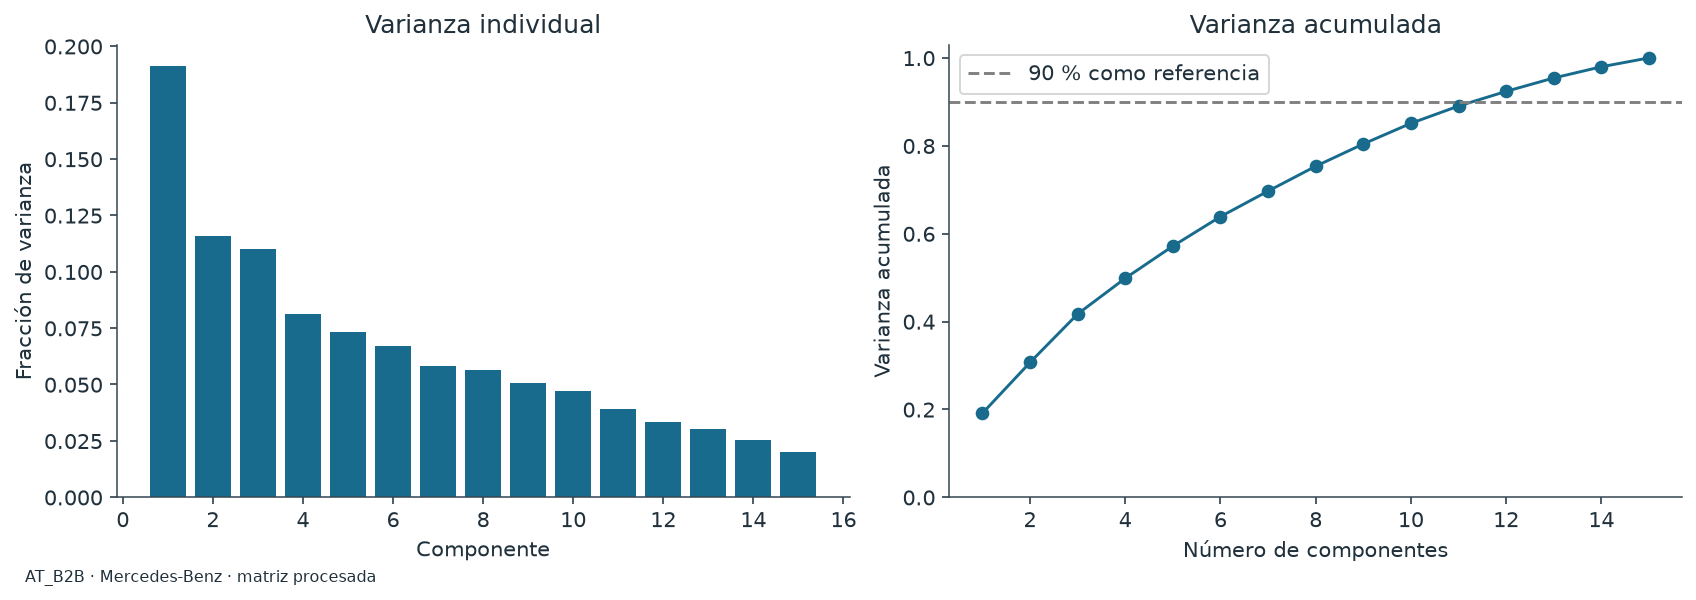

AT_B2C · varianza por componente


,Componente,explained_variance,Varianza explicada,Varianza acumulada
0,PC1,2.1610,0.1441,0.1441
1,PC2,1.5646,0.1043,0.2484
2,PC3,1.4609,0.0974,0.3458
3,PC4,1.2244,0.0816,0.4274
4,PC5,1.1986,0.0799,0.5073
5,PC6,1.1102,0.0740,0.5813
6,PC7,0.9968,0.0665,0.6478
7,PC8,0.9282,0.0619,0.7097
8,PC9,0.9106,0.0607,0.7704
9,PC10,0.7742,0.0516,0.8220


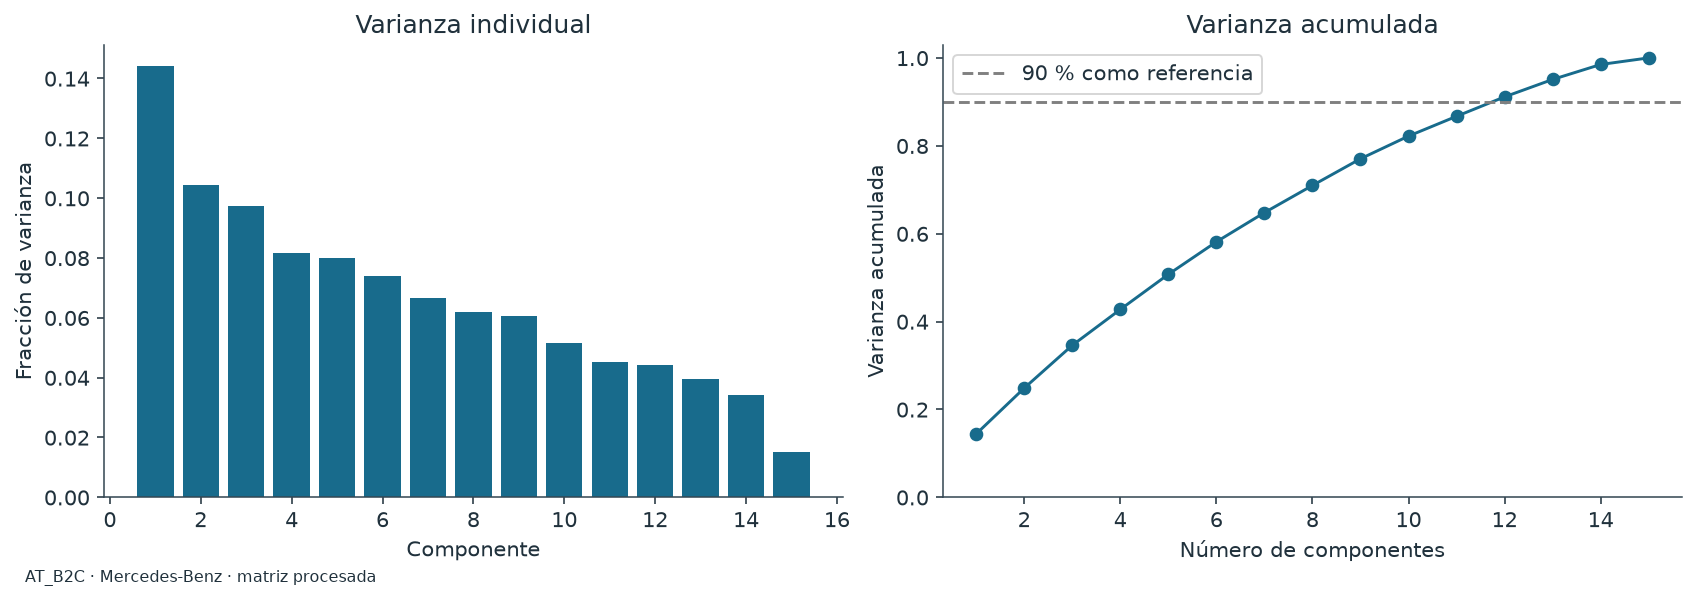

CH_B2B · varianza por componente


,Componente,explained_variance,Varianza explicada,Varianza acumulada
0,PC1,2.8334,0.1888,0.1888
1,PC2,1.5934,0.1062,0.2950
2,PC3,1.4806,0.0987,0.3937
3,PC4,1.2723,0.0848,0.4785
4,PC5,1.1776,0.0785,0.5570
5,PC6,0.9441,0.0629,0.6199
6,PC7,0.8791,0.0586,0.6785
7,PC8,0.8731,0.0582,0.7367
8,PC9,0.7860,0.0524,0.7890
9,PC10,0.7805,0.0520,0.8411


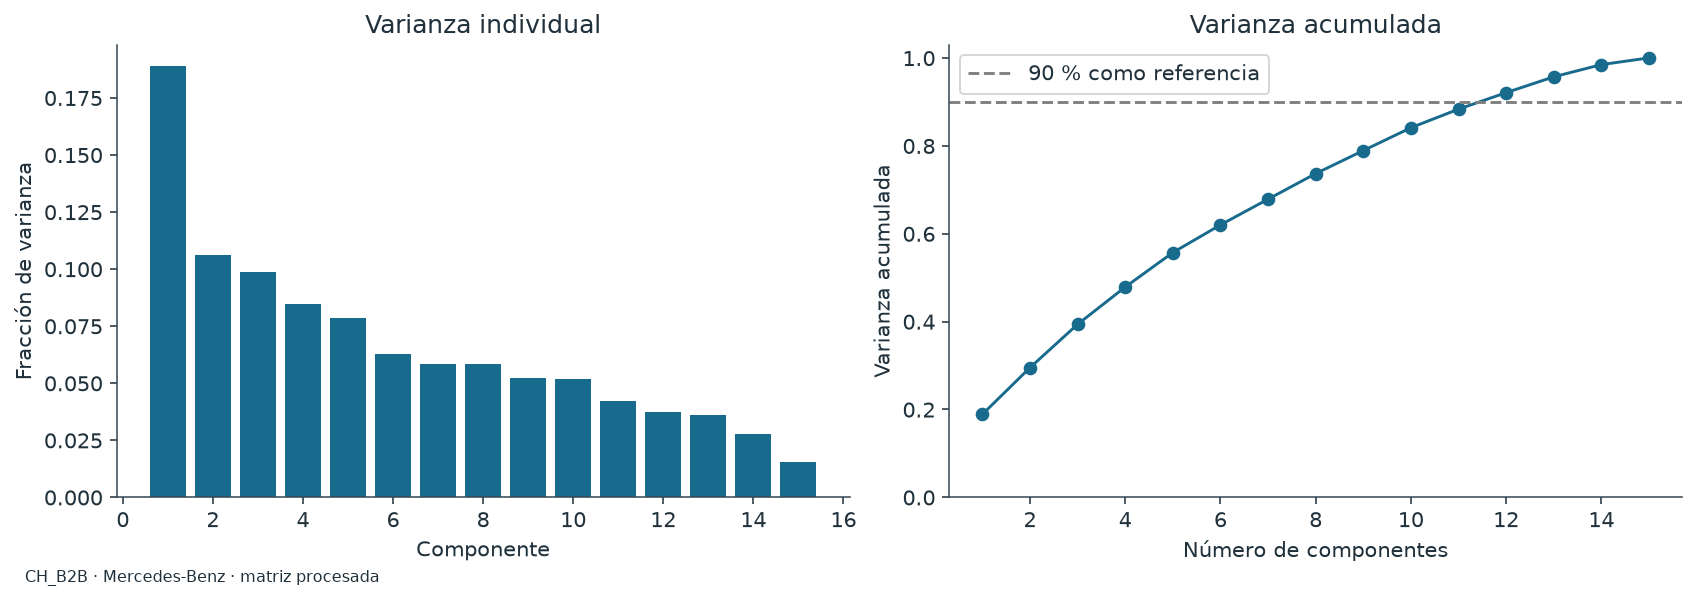

CH_B2C · varianza por componente


,Componente,explained_variance,Varianza explicada,Varianza acumulada
0,PC1,2.3293,0.1553,0.1553
1,PC2,1.5561,0.1037,0.2590
2,PC3,1.3944,0.0930,0.3520
3,PC4,1.2452,0.0830,0.4350
4,PC5,1.1313,0.0754,0.5104
5,PC6,0.9929,0.0662,0.5766
6,PC7,0.9651,0.0643,0.6410
7,PC8,0.9350,0.0623,0.7033
8,PC9,0.8706,0.0580,0.7613
9,PC10,0.8277,0.0552,0.8165


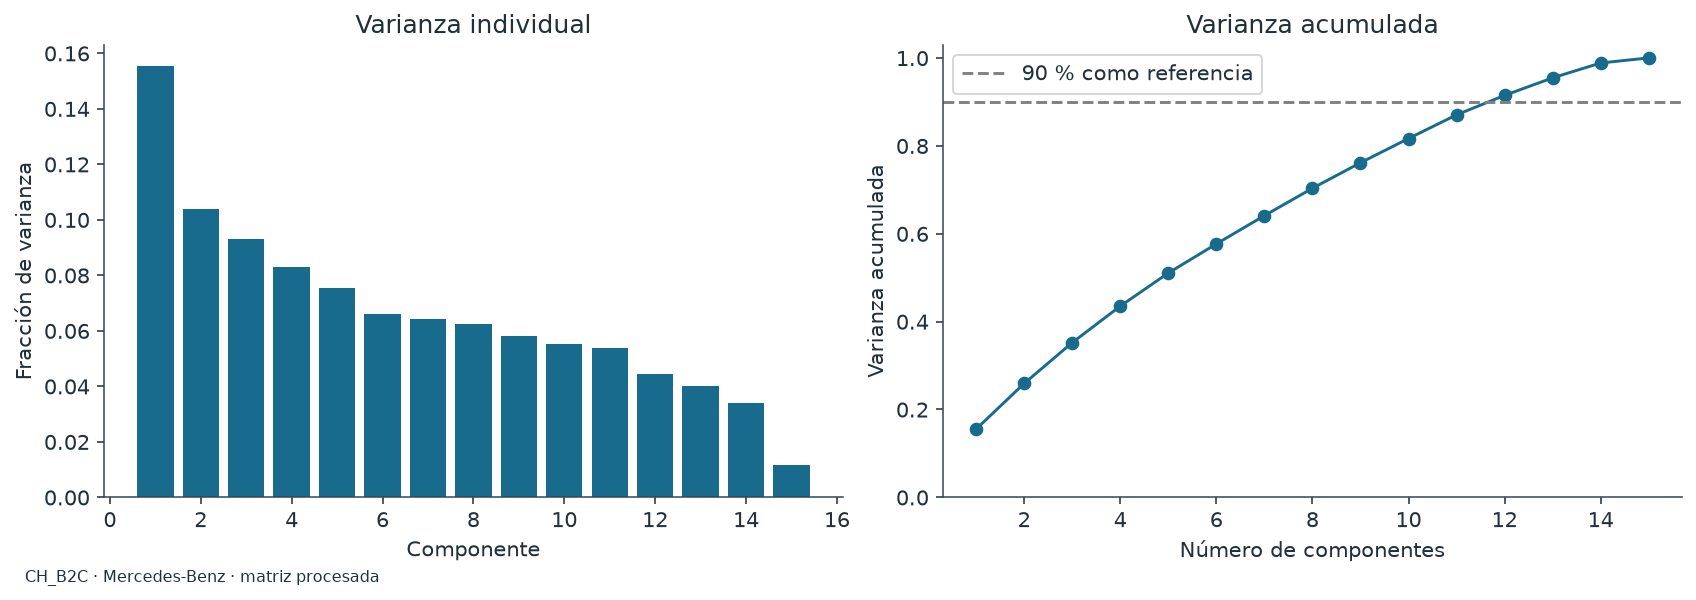

In [13]:
for segment, context in analyses.items():
    pca = context["pca"]
    display_table(pca.variance,segment+" · varianza por componente",max_rows=16)
    plot_pca_variance(pca)
    show_figures(segment)


## Proyectar las asignaciones ya conocidas

El color conserva las etiquetas de 03. Los círculos proceden de sus fronteras medidas en X, sin recalcularlas en PCA. Las columnas o bandas pueden reflejar coordenadas discretas. Para evitar saturación se muestran hasta 6.000 clientes, con presupuesto por cluster y semilla fija; la leyenda distingue volumen total y mostrado. Este muestreo favorece visibilidad de minorías y no representa densidad relativa.


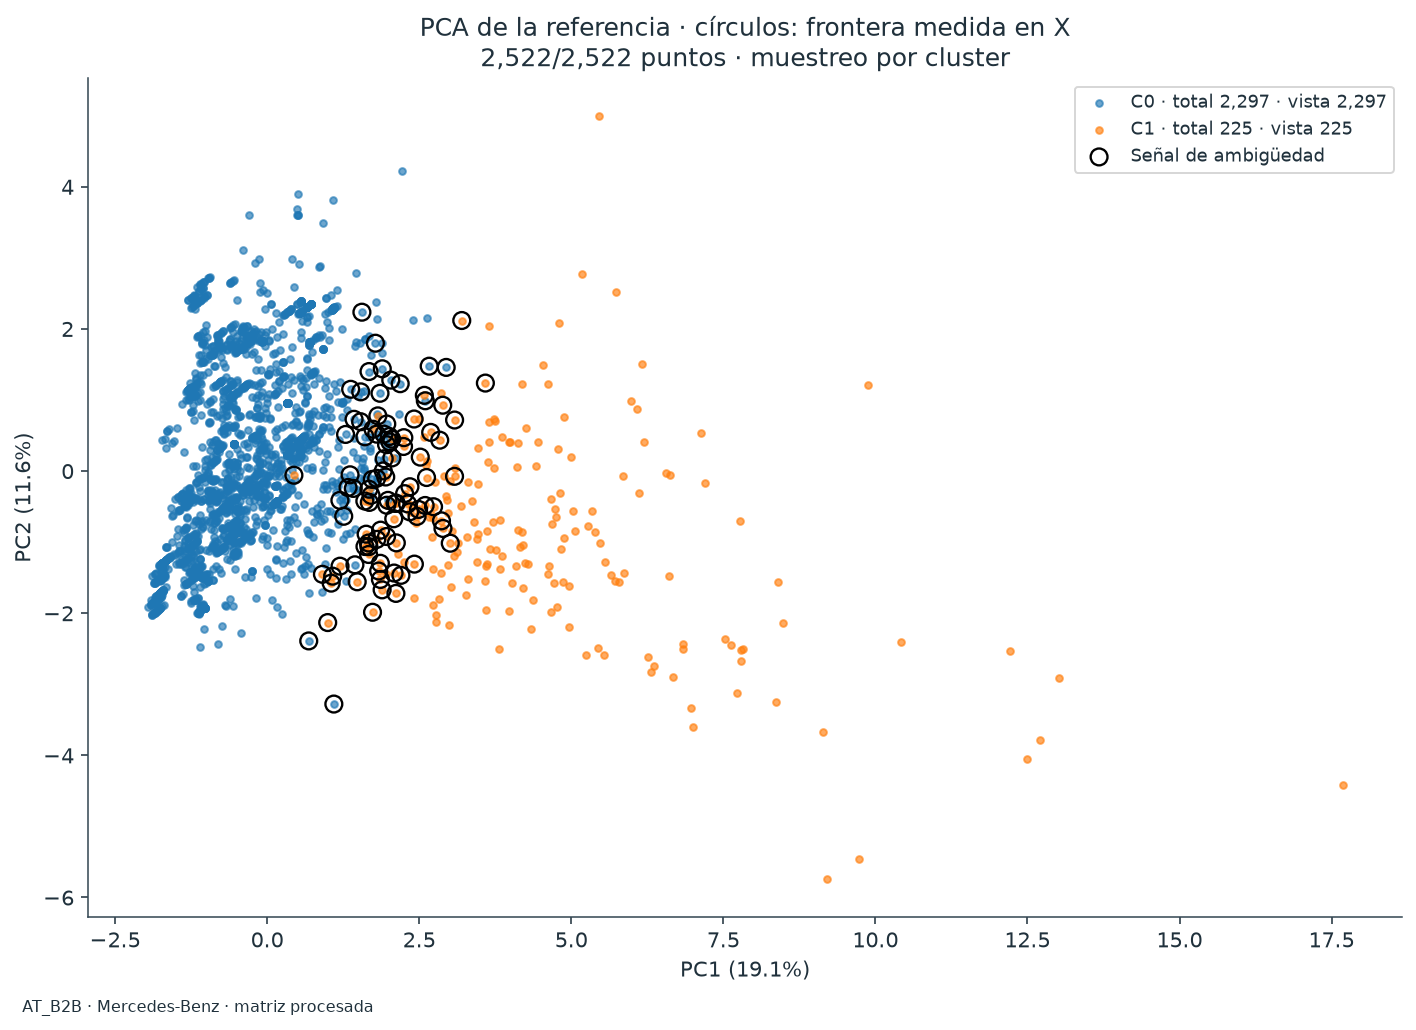

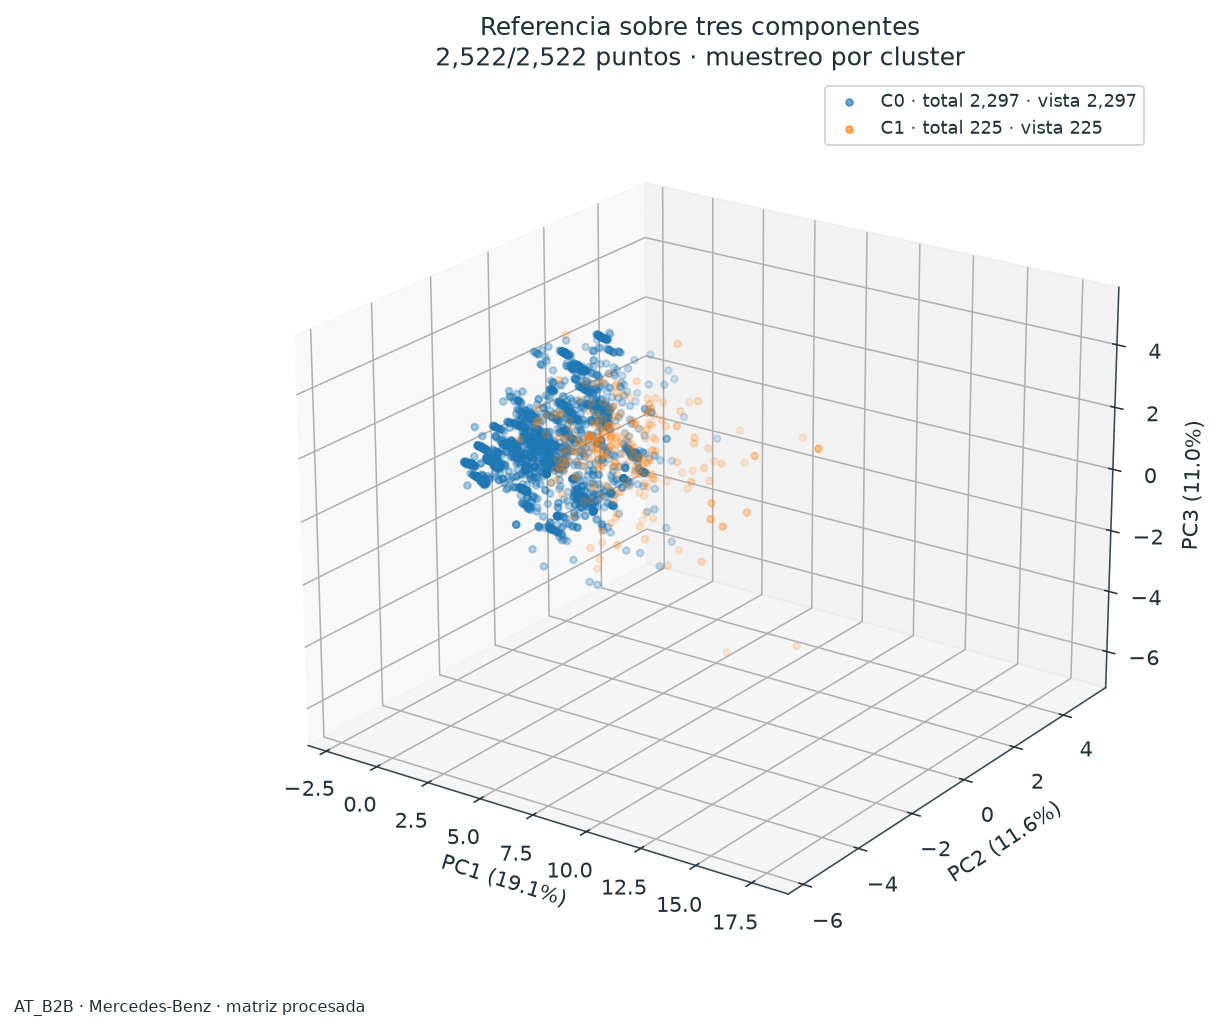

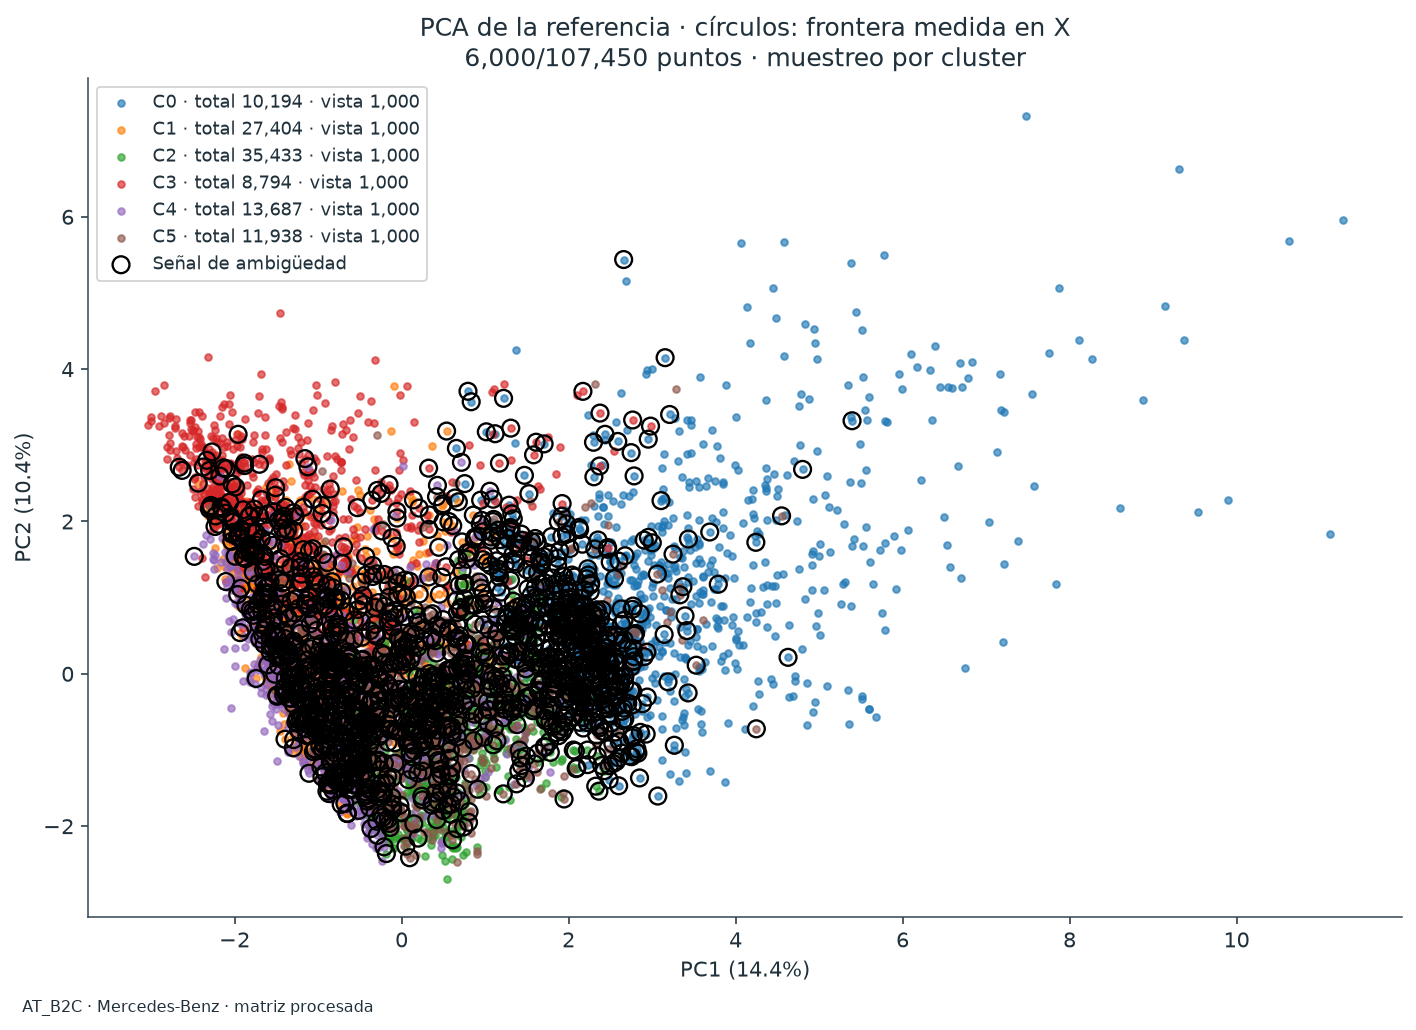

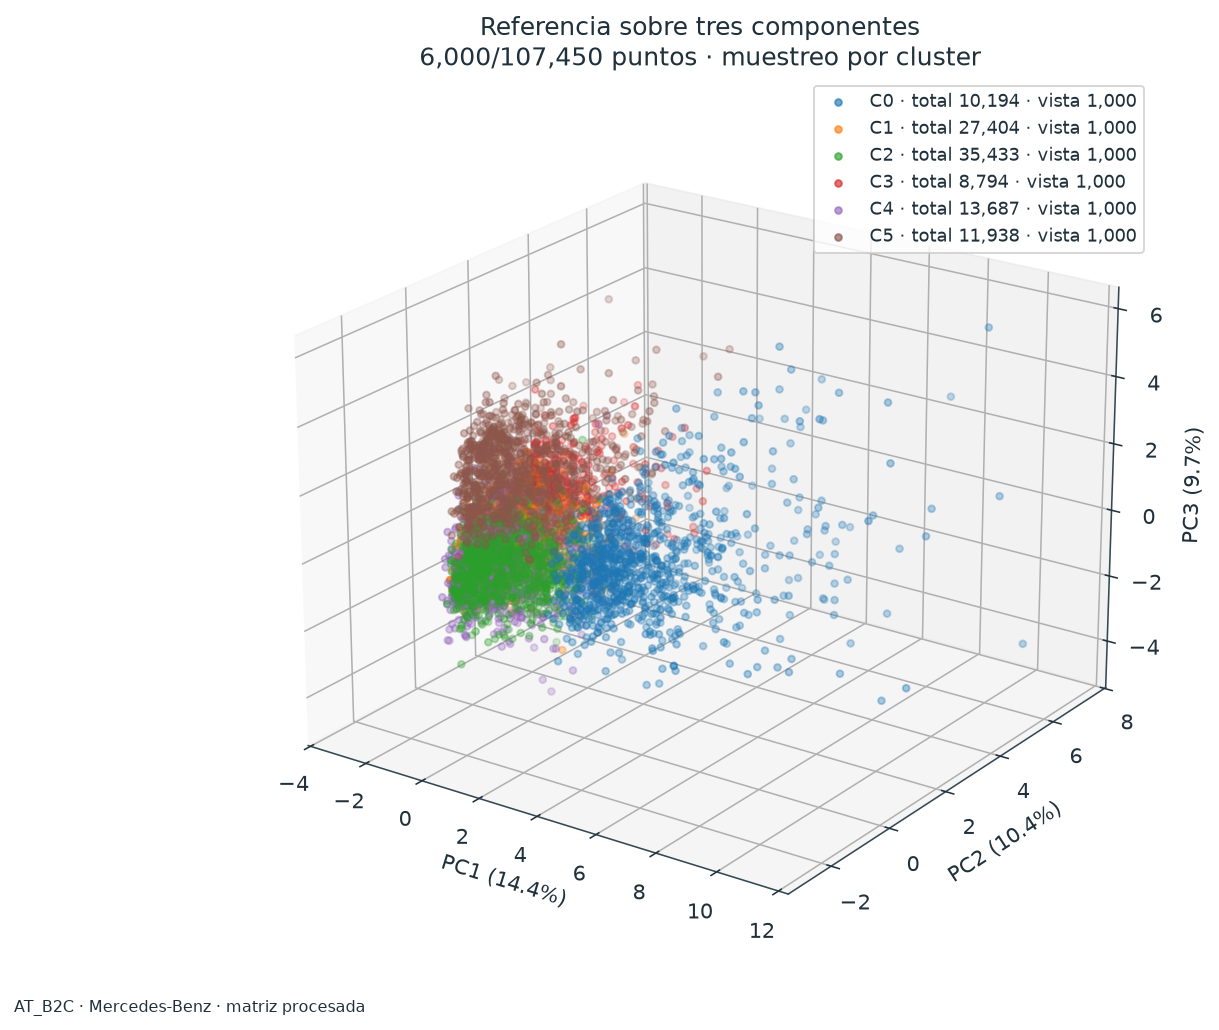

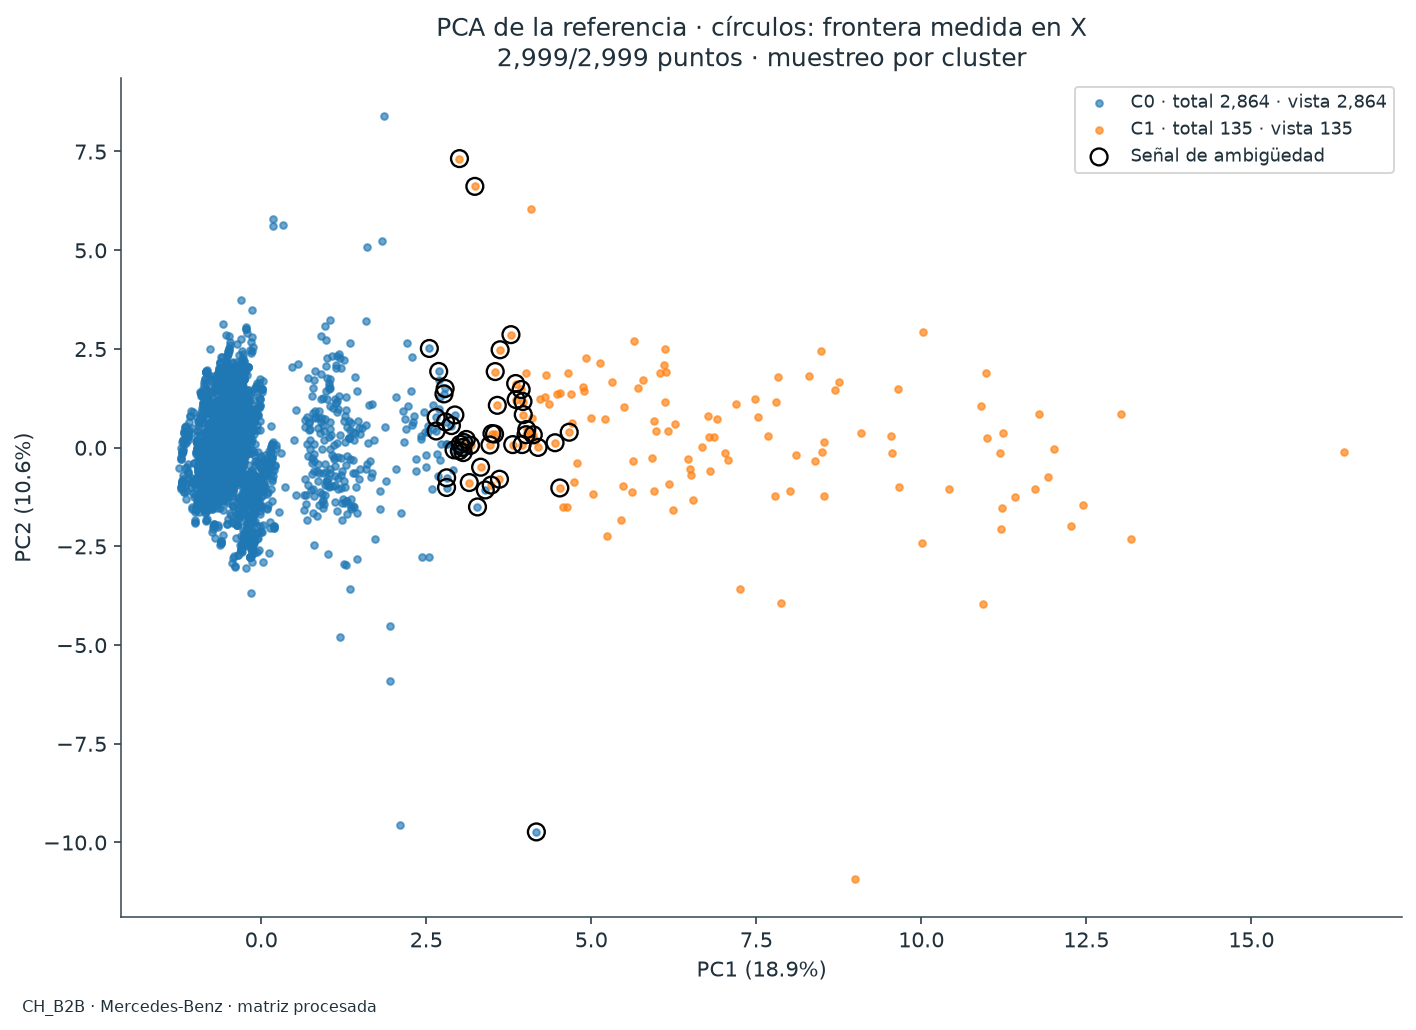

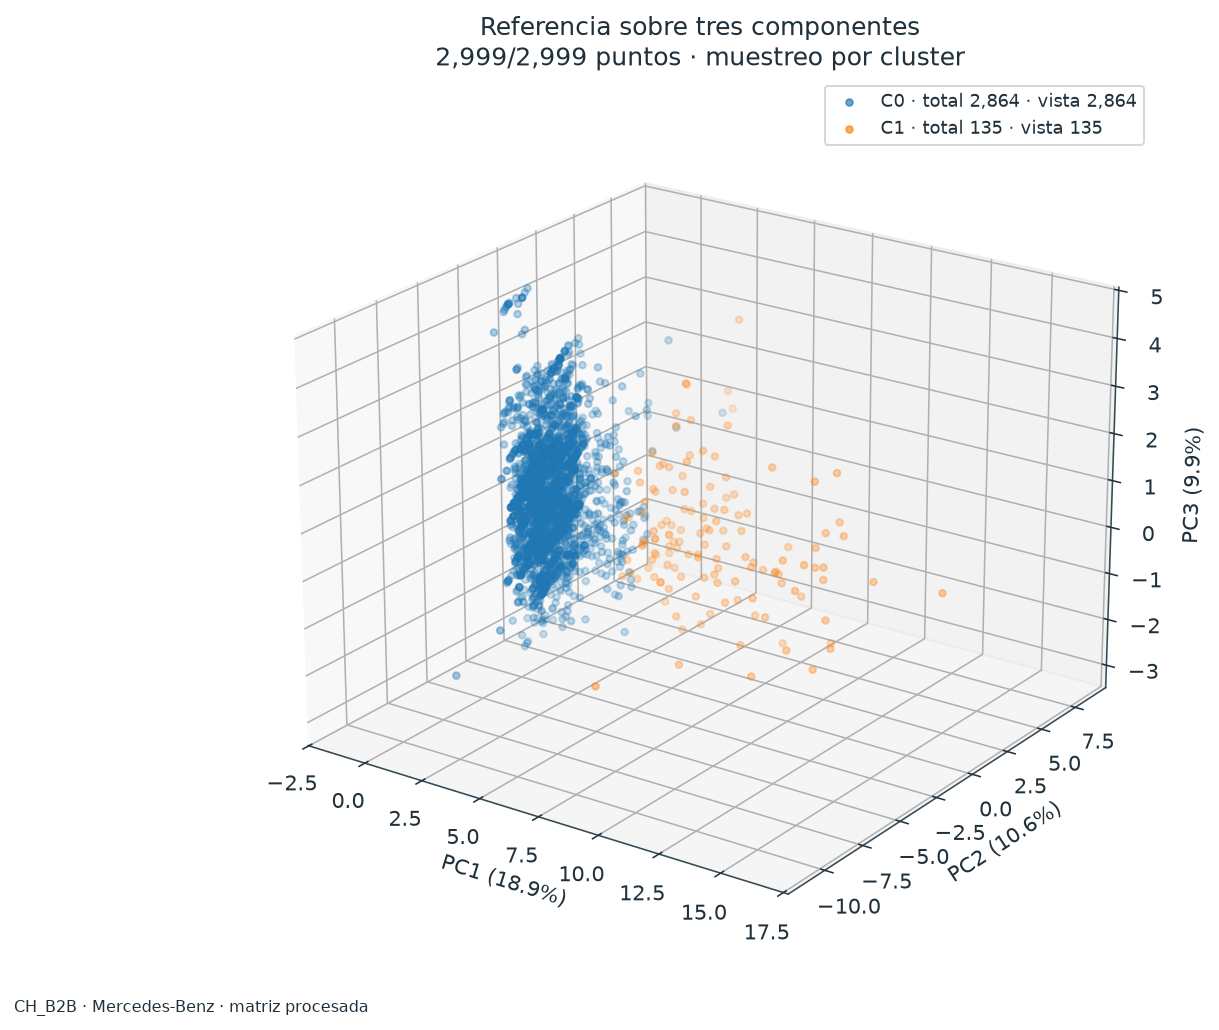

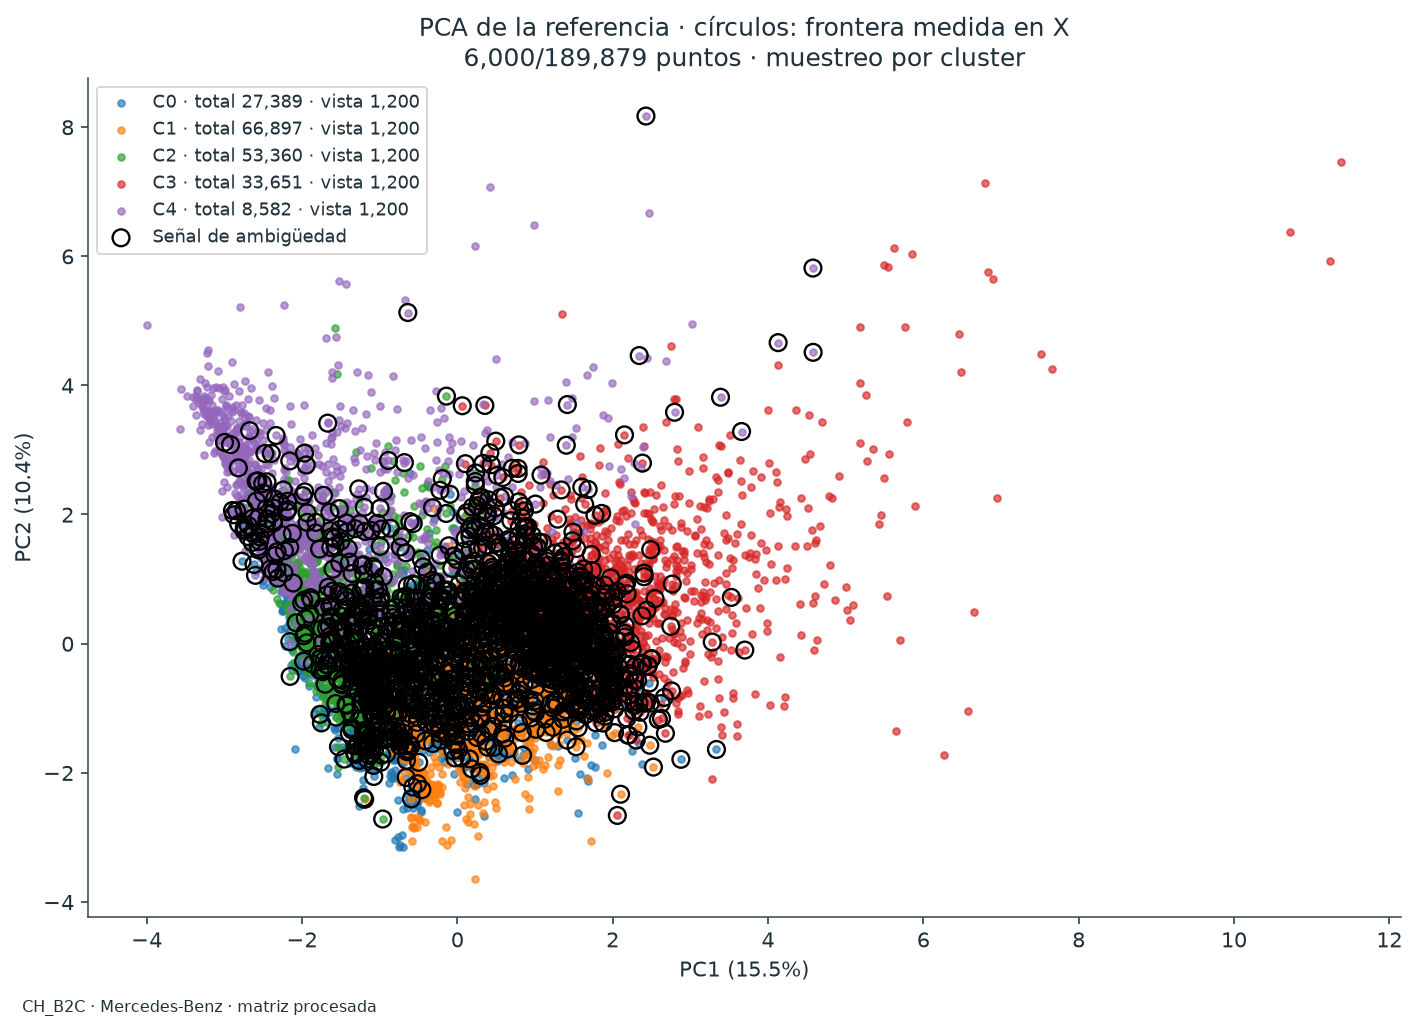

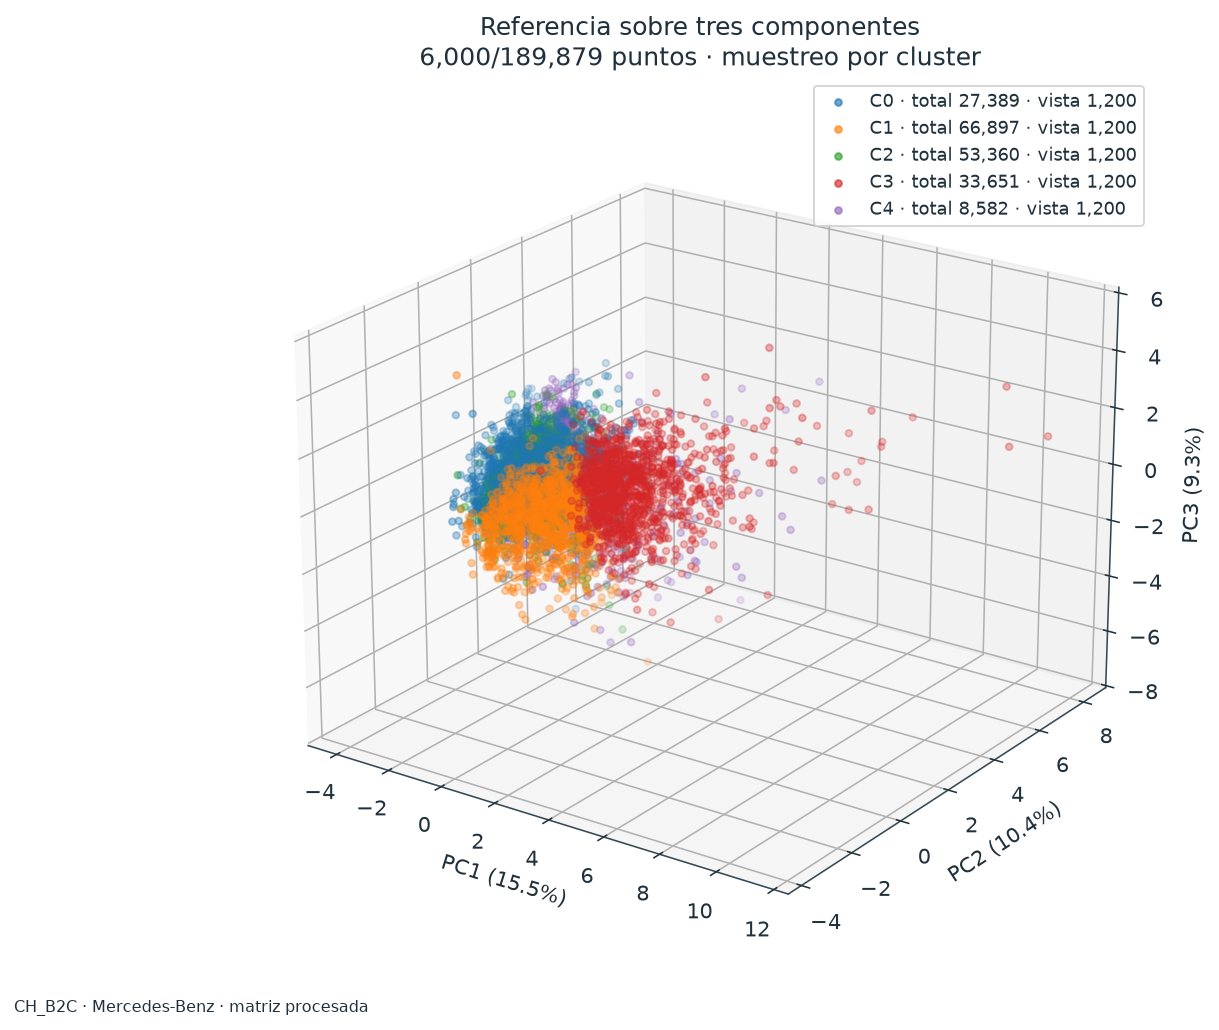

In [14]:
for segment, context in analyses.items():
    plot_pca_clusters(context["pca"],context["labels"],ambiguous=context["clients"]["near_boundary"],
        title="PCA de la referencia · círculos: frontera medida en X",
        max_points=PLOT_MAX_POINTS,random_state=SEED)
    if SHOW_3D and len(context["pca"].variance)>=3:
        plot_pca_clusters(context["pca"],context["labels"],dimensions=3,title="Referencia sobre tres componentes",
            max_points=PLOT_MAX_POINTS,random_state=SEED)
    show_figures(segment)


## Explorar la vista 3D dentro del notebook

El visor siguiente está embebido y no requiere librerías gráficas adicionales ni conexión. **Arrastrar** rota, la **rueda** amplía y la **leyenda** oculta grupos. Al pasar el cursor se muestra la clave técnica y las coordenadas. El botón **Descargar HTML interactivo** permite abrir la misma vista en un navegador. También se guarda un HTML por población en outputs/06; en Colab puede descargarse desde el panel Archivos. Si el entorno bloquea contenido activo, confiar en el notebook y ejecutar esta celda; las vistas estáticas anteriores siguen disponibles. La proyección usa la misma escala geométrica para los tres ejes.


In [15]:
for segment, context in analyses.items():
    if INTERACTIVE_3D and len(context["pca"].variance)>=3:
        view = interactive_pca_view(context["pca"],context["labels"],segment=segment,
            max_points=PLOT_MAX_POINTS,random_state=SEED)
        path = view.write_html(OUTPUT_DIR/f"{segment}_PCA_3D.html")
        context["interactive_path"] = str(path)
        display(view)
        print(f"{segment} · vista interactiva guardada en {path}")


Vista PCA 3D: arrastrar para rotar, rueda para zoom y leyenda para filtrar.

AT_B2B · vista interactiva guardada en outputs\06\522990f5\AT_B2B_PCA_3D.html


Vista PCA 3D: arrastrar para rotar, rueda para zoom y leyenda para filtrar.

AT_B2C · vista interactiva guardada en outputs\06\522990f5\AT_B2C_PCA_3D.html


Vista PCA 3D: arrastrar para rotar, rueda para zoom y leyenda para filtrar.

CH_B2B · vista interactiva guardada en outputs\06\522990f5\CH_B2B_PCA_3D.html


Vista PCA 3D: arrastrar para rotar, rueda para zoom y leyenda para filtrar.

CH_B2C · vista interactiva guardada en outputs\06\522990f5\CH_B2C_PCA_3D.html


## Vista complementaria: separar proyección de pertenencia

La vista PC1–PC3 permite examinar estructura que PC1–PC2 oculta; las etiquetas y las alertas siguen siendo las de la representación de modelado. Las figuras Matplotlib son estáticas; el visor HTML anterior permite rotar sin configurar un backend. Ningún solapamiento visual demuestra pertenencia múltiple: ese diagnóstico corresponde al GMM de 05.


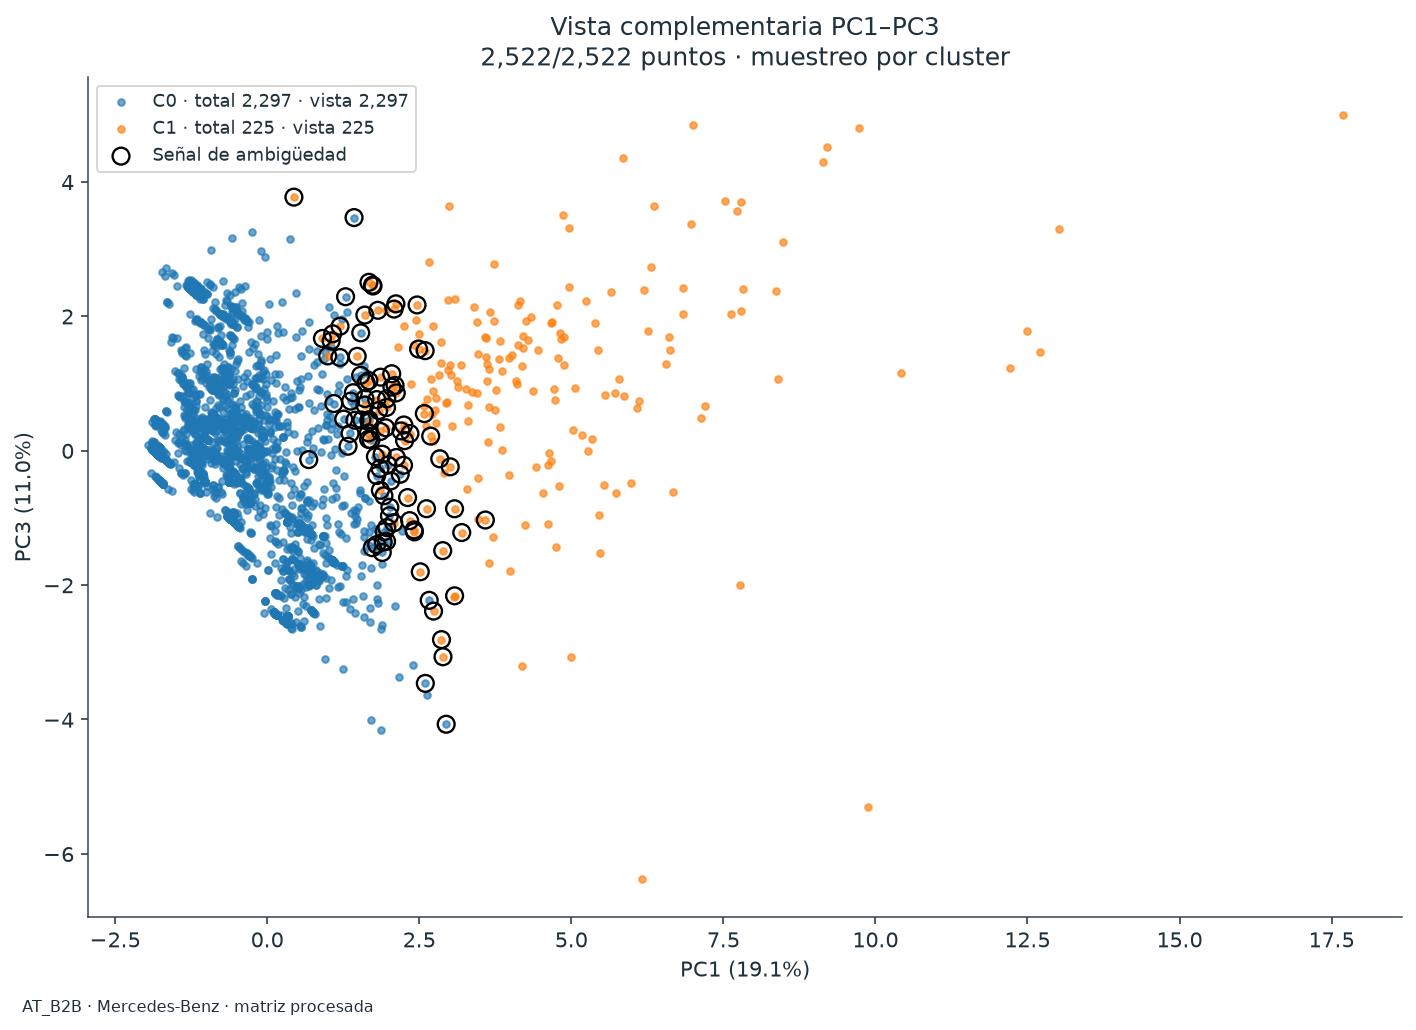

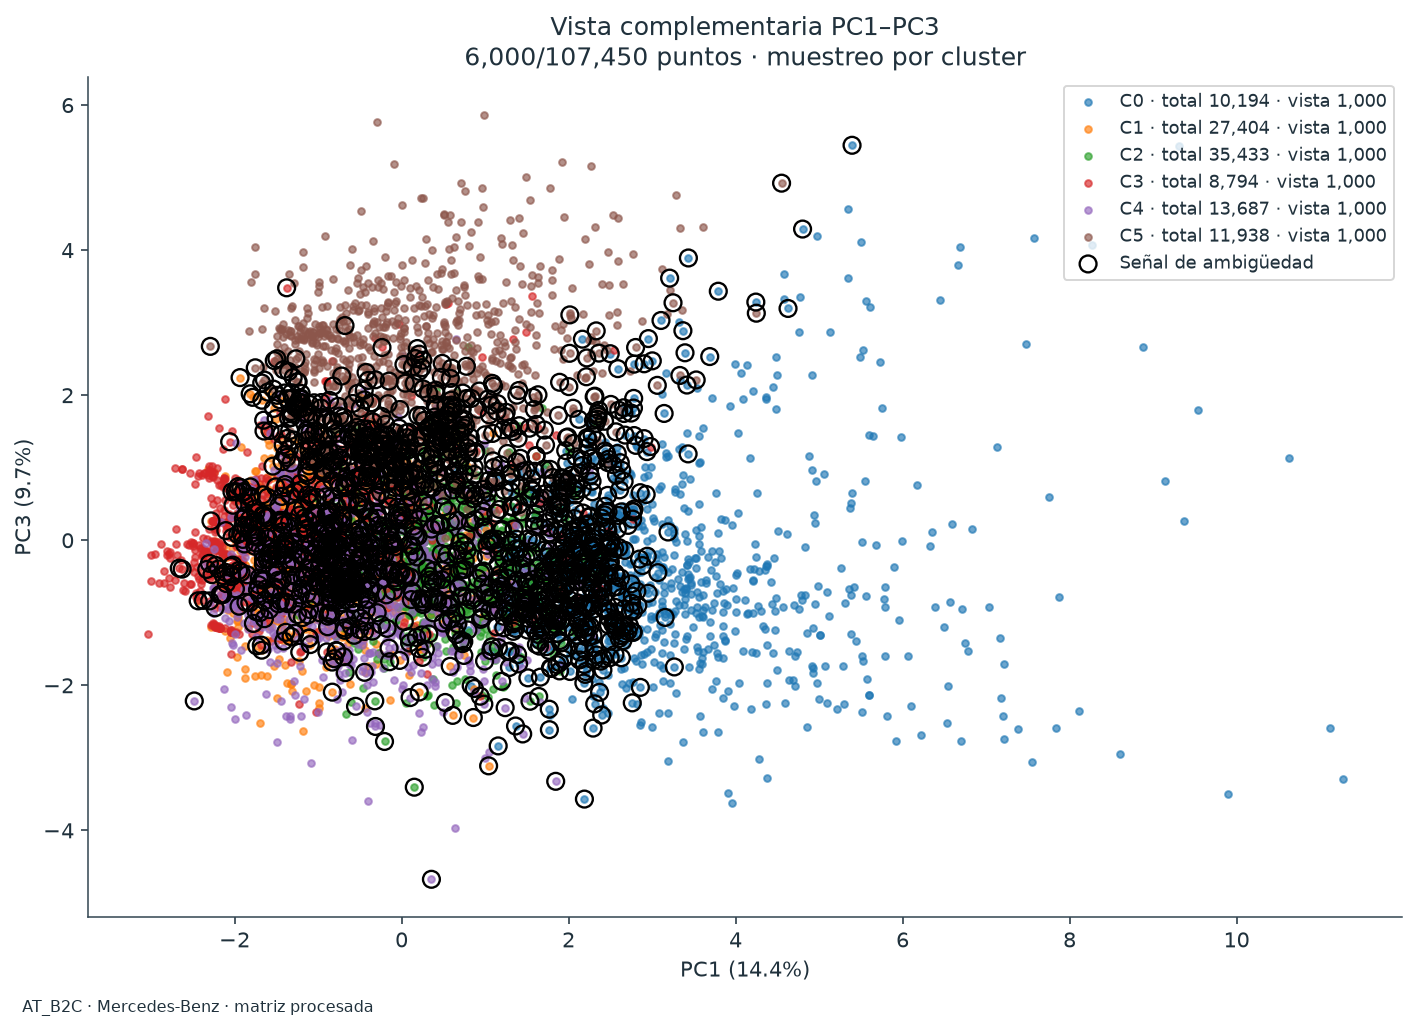

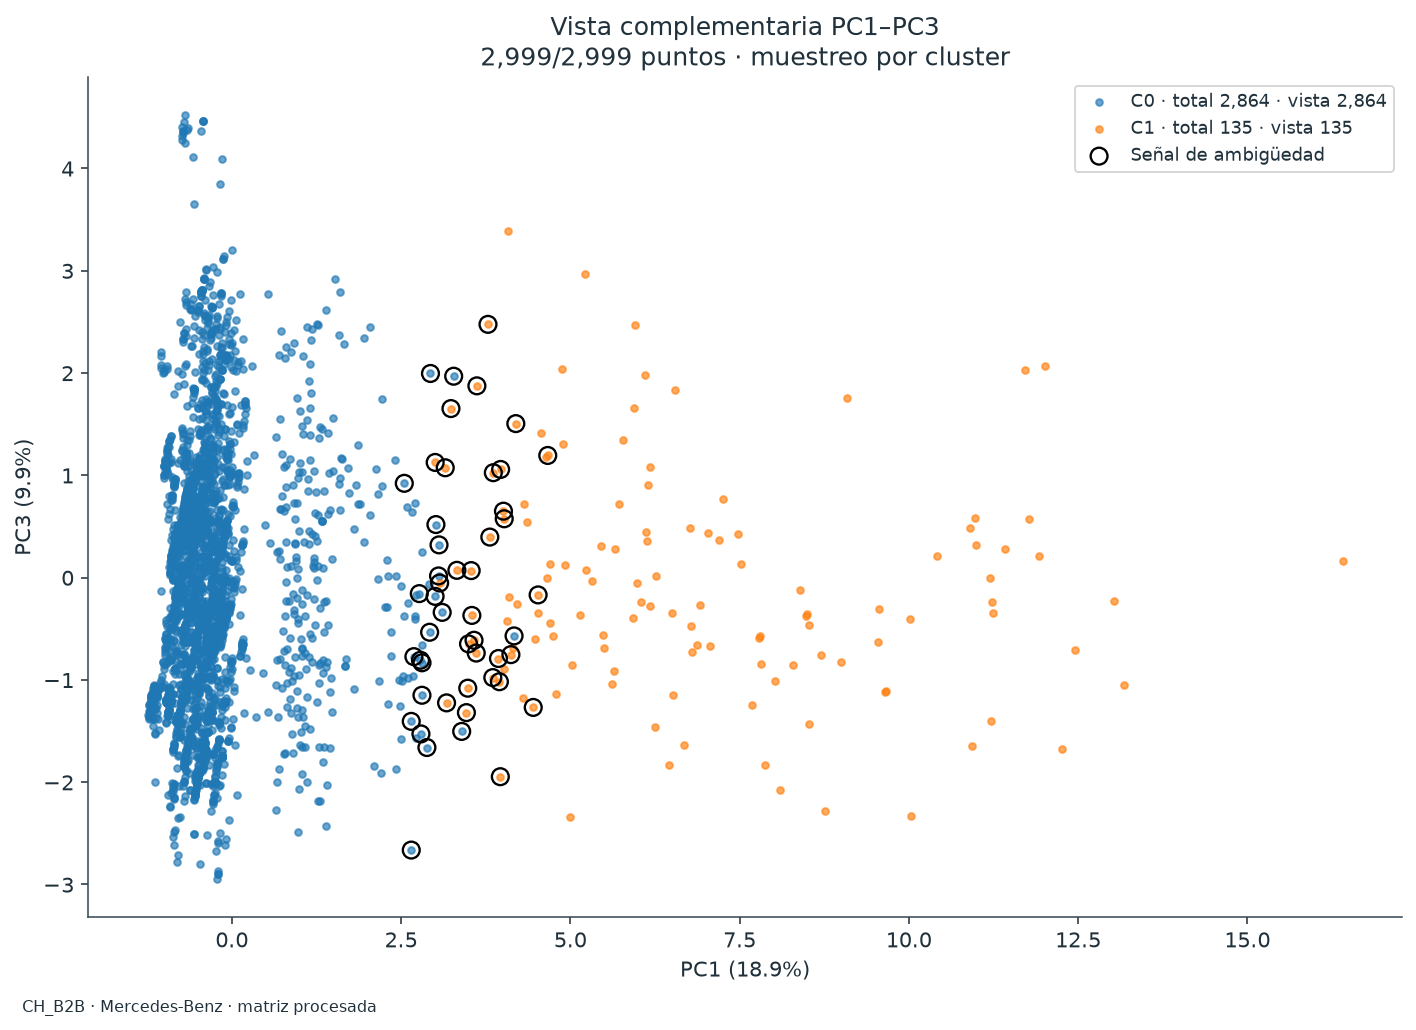

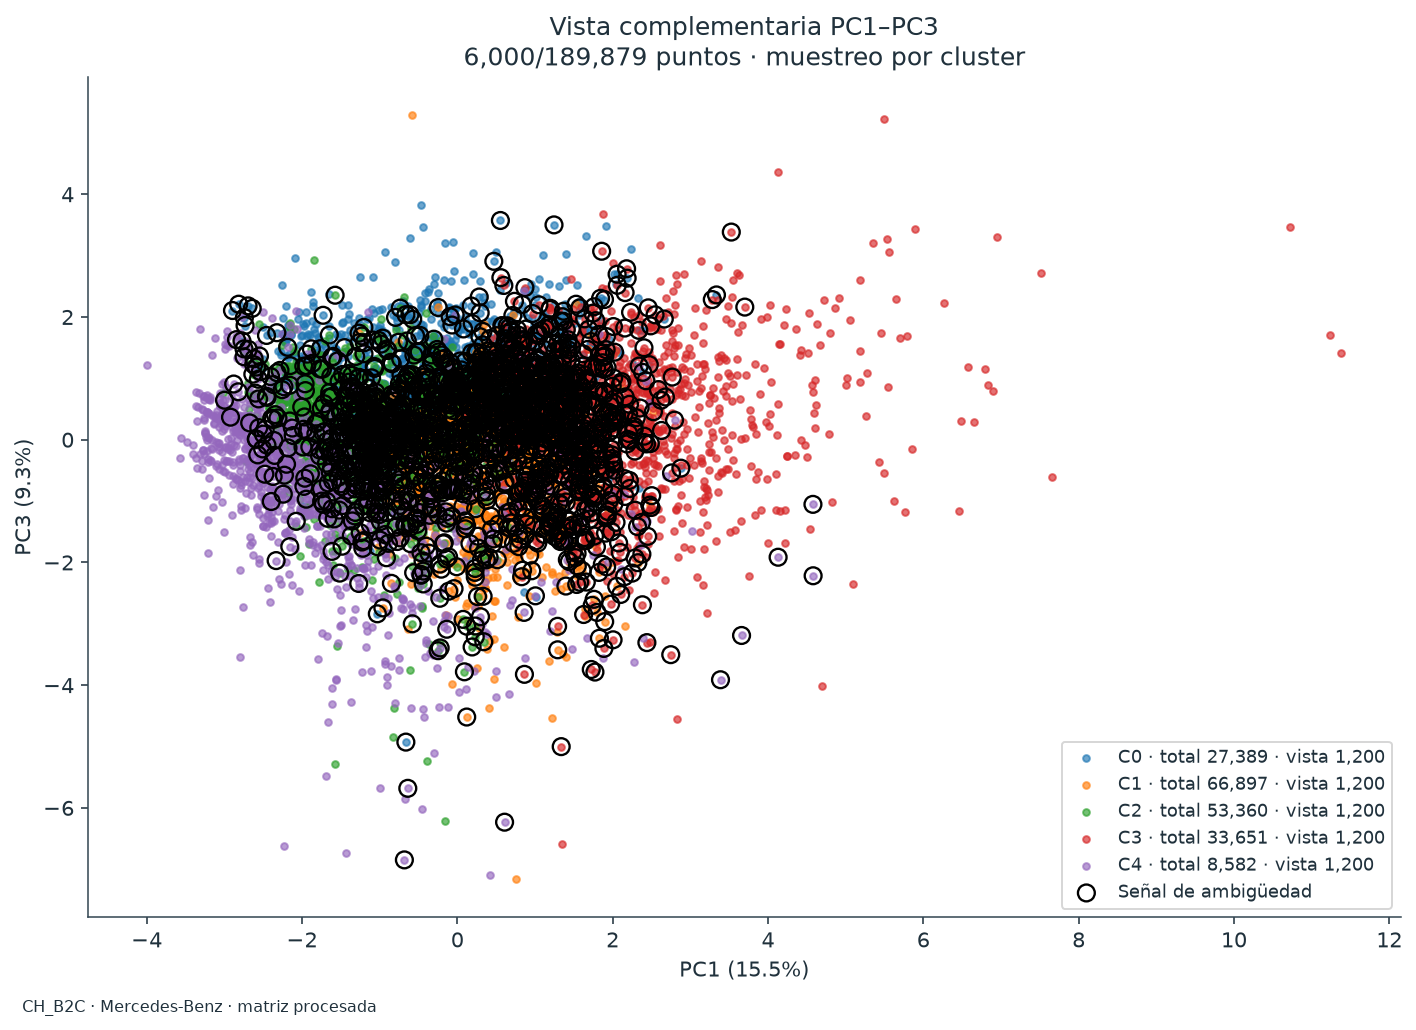

In [16]:
for segment, context in analyses.items():
    if len(context["pca"].variance)>=3:
        plot_pca_clusters(context["pca"],context["labels"],components=(0,2),
            ambiguous=context["clients"]["near_boundary"],title="Vista complementaria PC1–PC3",
            max_points=PLOT_MAX_POINTS,random_state=SEED)
        show_figures(segment)


## Variables que sostienen los ejes

axis_weight es el coeficiente del autovector, loading lo multiplica por √varianza y squared_contribution es su cuadrado, que suma 1 por componente. Ninguna de estas cantidades es importancia causal para una campaña. Contrastar la dominancia del eje con los perfiles de 04.


In [17]:
for segment, context in analyses.items():
    contributions=context["pca"].contributions
    top=(contributions.assign(magnitude=contributions["axis_weight"].abs())
        .sort_values("magnitude",ascending=False).groupby("component",sort=False).head(3))
    first=context["pca"].variance["component"].head(3)
    view=top.loc[top["component"].isin(first)]
    display_table(view,segment+" · principales combinaciones de variables")
    context["pc1_driver"]=view.loc[view["component"]=="PC1"].iloc[0]["feature"]
    keep_table(segment,"contribuciones PCA",contributions)


AT_B2B · principales combinaciones de variables


,Componente,Feature,axis_weight,loading,squared_contribution,magnitude
24,PC2,population,0.5254,0.6922,0.2760,0.5254
42,PC3,speed_median,0.4857,0.6247,0.2359,0.4857
43,PC3,fuel_consumption_average,-0.4818,-0.6197,0.2321,0.4818
33,PC3,months_as_mb_customer,0.4802,0.6177,0.2306,0.4802
19,PC2,currently_connected_vehicles,-0.4282,-0.5642,0.1834,0.4282
6,PC1,workshop_visits_warranty_goodwill,0.4281,0.7251,0.1833,0.4281
22,PC2,marketing_receptivity_score,-0.4052,-0.5339,0.1642,0.4052
2,PC1,is_current_vehicle,0.3891,0.6590,0.1514,0.3891
14,PC1,operating_hours_total,0.3885,0.6580,0.1510,0.3885


AT_B2C · principales combinaciones de variables


,Componente,Feature,axis_weight,loading,squared_contribution,magnitude
39,PC3,population,0.6160,0.7445,0.3794,0.6160
18,PC2,months_as_mb_customer,0.6091,0.7619,0.3711,0.6091
38,PC3,purchasing_power_per_inhabitant_eur,-0.5659,-0.6840,0.3202,0.5659
5,PC1,workshop_frequency_yearly,0.5320,0.7820,0.2830,0.5320
6,PC1,workshop_visits_warranty_goodwill,0.5158,0.7582,0.2660,0.5158
19,PC2,currently_connected_vehicles,0.4032,0.5043,0.1625,0.4032
10,PC1,has_telemetry_active,0.3798,0.5583,0.1442,0.3798
17,PC2,is_current_vehicle,-0.3786,-0.4735,0.1433,0.3786
42,PC3,speed_median,-0.3656,-0.4419,0.1337,0.3656


CH_B2B · principales combinaciones de variables


,Componente,Feature,axis_weight,loading,squared_contribution,magnitude
33,PC3,months_as_mb_customer,0.6584,0.8011,0.4335,0.6584
28,PC2,fuel_consumption_average,0.5959,0.7522,0.3550,0.5959
26,PC2,trip_distance_median,-0.5651,-0.7133,0.3193,0.5651
6,PC1,workshop_visits_warranty_goodwill,0.5030,0.8467,0.2530,0.5030
5,PC1,workshop_frequency_yearly,0.4811,0.8099,0.2315,0.4811
38,PC3,purchasing_power_per_inhabitant_eur,0.4633,0.5637,0.2146,0.4633
2,PC1,is_current_vehicle,0.4286,0.7214,0.1837,0.4286
16,PC2,vehicle_age_years,0.4262,0.5380,0.1816,0.4262
34,PC3,currently_connected_vehicles,0.3582,0.4359,0.1283,0.3582


CH_B2C · principales combinaciones de variables


,Componente,Feature,axis_weight,loading,squared_contribution,magnitude
18,PC2,months_as_mb_customer,0.5737,0.7157,0.3292,0.5737
42,PC3,speed_median,0.5424,0.6405,0.2942,0.5424
5,PC1,workshop_frequency_yearly,0.5332,0.8138,0.2843,0.5332
6,PC1,workshop_visits_warranty_goodwill,0.5087,0.7763,0.2587,0.5087
10,PC1,has_telemetry_active,0.3760,0.5739,0.1414,0.3760
16,PC2,vehicle_age_years,0.3593,0.4482,0.1291,0.3593
19,PC2,currently_connected_vehicles,0.3450,0.4304,0.1191,0.3450
37,PC3,marketing_receptivity_score,-0.3263,-0.3854,0.1065,0.3263
30,PC3,age_range_encoded,0.3260,0.3849,0.1063,0.3260


## Lectura para campañas

Si una componente se concentra en una medida de uso, el gráfico puede separar rangos de esa medida más que perfiles comerciales diversos. Si 2D conserva poca varianza, las decisiones tampoco pueden basarse en una frontera dibujada. Ambas situaciones justifican el estrés de representación de 07.


In [18]:
for segment, context in analyses.items():
    variance=context["pca"].variance
    ratio=float(variance["explained_ratio"].head(2).sum())
    reached=np.flatnonzero(variance["cumulative_ratio"].to_numpy()>=.9)
    n90=int(reached[0]+1) if len(reached) else "no alcanzado"
    context["findings"]=[f"En el CSV recibido, PC1 explicaba {context['input_pca'].variance['explained_ratio'].iloc[0]:.1%}. Tras la representación {SCALING_POLICY} definida en 03, explica {variance['explained_ratio'].iloc[0]:.1%}; su mayor coeficiente corresponde a {context['pc1_driver']}.",
        f"Los dos primeros ejes conservan {ratio:.1%}; hacen falta {n90} componentes para 90 %.",
        "El signo de los coeficientes describe combinaciones de coordenadas procesadas, no unidades originales ni causalidad.",
        "La segmentación no cambia. Una campaña necesita señales verificadas de relación o necesidad, además de separación visual."]
    context["entry"]["pca_variance"]=json.loads(variance.to_json(orient="records"))
    context["entry"]["steps"]=sorted(set(context["entry"]["steps"]+["06"]))
    display(ReportPanel(segment+" · interpretación de PCA",{},context["findings"],"Proyección y explicación de varianza; etiquetas conservadas"))


# AT_B2B · interpretación de PCA

Proyección y explicación de varianza; etiquetas conservadas

| Indicador | Resultado |
| --- | --- |

- En el CSV recibido, PC1 explicaba 45.2%. Tras la representación standardize definida en 03, explica 19.1%; su mayor coeficiente corresponde a workshop_visits_warranty_goodwill.
- Los dos primeros ejes conservan 30.7%; hacen falta 12 componentes para 90 %.
- El signo de los coeficientes describe combinaciones de coordenadas procesadas, no unidades originales ni causalidad.
- La segmentación no cambia. Una campaña necesita señales verificadas de relación o necesidad, además de separación visual.

# AT_B2C · interpretación de PCA

Proyección y explicación de varianza; etiquetas conservadas

| Indicador | Resultado |
| --- | --- |

- En el CSV recibido, PC1 explicaba 80.0%. Tras la representación standardize definida en 03, explica 14.4%; su mayor coeficiente corresponde a workshop_frequency_yearly.
- Los dos primeros ejes conservan 24.8%; hacen falta 12 componentes para 90 %.
- El signo de los coeficientes describe combinaciones de coordenadas procesadas, no unidades originales ni causalidad.
- La segmentación no cambia. Una campaña necesita señales verificadas de relación o necesidad, además de separación visual.

# CH_B2B · interpretación de PCA

Proyección y explicación de varianza; etiquetas conservadas

| Indicador | Resultado |
| --- | --- |

- En el CSV recibido, PC1 explicaba 18.4%. Tras la representación standardize definida en 03, explica 18.9%; su mayor coeficiente corresponde a workshop_visits_warranty_goodwill.
- Los dos primeros ejes conservan 29.5%; hacen falta 12 componentes para 90 %.
- El signo de los coeficientes describe combinaciones de coordenadas procesadas, no unidades originales ni causalidad.
- La segmentación no cambia. Una campaña necesita señales verificadas de relación o necesidad, además de separación visual.

# CH_B2C · interpretación de PCA

Proyección y explicación de varianza; etiquetas conservadas

| Indicador | Resultado |
| --- | --- |

- En el CSV recibido, PC1 explicaba 83.8%. Tras la representación standardize definida en 03, explica 15.5%; su mayor coeficiente corresponde a workshop_frequency_yearly.
- Los dos primeros ejes conservan 25.9%; hacen falta 12 componentes para 90 %.
- El signo de los coeficientes describe combinaciones de coordenadas procesadas, no unidades originales ni causalidad.
- La segmentación no cambia. Una campaña necesita señales verificadas de relación o necesidad, además de separación visual.

## Alcance y siguiente decisión

La última entrega someterá los grupos a exclusiones y a deformaciones explícitas de datos. La varianza explicada no sustituye la estabilidad ni la validación incremental de las campañas. [PCA](https://scikit-learn.org/stable/modules/decomposition.html#pca).


In [19]:
# El paquete conserva los resultados previos; cada cuaderno añade solo su aportación.
save_study(study, REFERENCE_FILE)
RUN_REPORT = dict(step="06", source="real", versions=VERSIONS,
    segments=[dict(segment_id=segment, clients=context["data"].n_samples,
                   features=context["data"].n_features, k=int(context["model"].n_clusters),
                   scaling_policy=context["representation"]["policy"])
              for segment, context in analyses.items()],
    findings={segment:context["findings"] for segment,context in analyses.items()},
    elapsed_seconds=round(perf_counter()-STARTED,3))
print("Resultados actualizados en " + REFERENCE_FILE + ". Para continuar en otra sesión, conservar este paquete junto a los CSV.")


Resultados actualizados en segmentacion_ml.zip. Para continuar en otra sesión, conservar este paquete junto a los CSV.
